<div style="background: linear-gradient(135deg, #0f2027, #203a43, #2c5364); color: white; padding: 28px; border-radius: 14px; text-align: center;">

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQyZM6yEqo5titU26Bl4niD1G9_uoQ_eFPjotLnk7rp7LQB1C8RtbYsC2HN&s=10" width="100" height="120">

# MVP - Engenharia de Dados

## Nome: Carlos Leonardo Souza Cardoso

## Matrícula: 4052025000555

### Análise de Dados Meteorológicos do estado do Rio de Janeiro

</div>

# Introdução

Este **MVP** tem como objetivo demonstrar a aplicação de um pipeline de Engenharia de Dados em um ambiente de nuvem, utilizando o Databricks como plataforma para processamento, organização e análise dos dados. Como estudo de caso, foi utilizado um conjunto de dados meteorológicos, contendo informações de estações meteorológicas, como precipitação, temperatura, umidade, pressão atmosférica e vento. Para reduzir o escopo da análise, foram considerados os registros referentes ao estado do Rio de Janeiro.

O processo contempla etapas de aquisição e preparação dos dados, filtragem, padronização de colunas, conversão e validação de tipos, organização em diferentes estágios e, posteriormente, análise exploratória e visualização. Devido às limitações da versão gratuita do Databricks e ao volume dos arquivos brutos, algumas etapas iniciais, como o download e a filtragem dos dados, foram realizadas externamente à plataforma. Os dados preparados são então disponibilizados ao Databricks para continuidade do pipeline, permitindo explorar estatísticas descritivas, séries temporais e eventos de precipitação, demonstrando na prática o fluxo de tratamento e análise de dados em um ambiente de nuvem.


Os dados utilizados são do INMET, adquiridos do **Kaggle**. Dataset: [Metereological Data - Brazil (2018-2024) - INMET](https://www.kaggle.com/datasets/gnomows/dados-metereologicos-2018-2024-inmet/data)

# Contextualização do problema


O estado do Rio de Janeiro apresenta grande diversidade geográfica, com regiões serranas, áreas litorâneas, baixadas e centros urbanos densamente ocupados. Essas características influenciam tanto o comportamento das condições meteorológicas quanto os impactos causados por eventos de chuva intensa.

Em regiões como Petrópolis, Teresópolis e Nova Friburgo, a combinação entre relevo acidentado, ocupação de encostas e precipitação elevada pode aumentar a ocorrência de movimentos de massa. Já na Região Metropolitana e na Baixada Fluminense, a impermeabilização do solo e a concentração urbana favorecem alagamentos, enxurradas e problemas de drenagem.

Além da precipitação, variáveis como temperatura, umidade relativa e ponto de orvalho ajudam a caracterizar as condições atmosféricas associadas aos diferentes padrões meteorológicos. Entretanto, para que essas informações possam ser analisadas de forma consistente, é necessário organizar, padronizar e processar grandes volumes de dados provenientes de diferentes estações.

Nesse contexto, este trabalho utiliza técnicas de Engenharia de Dados, com Apache Spark e Databricks, para preparar e analisar dados meteorológicos do estado do Rio de Janeiro. O objetivo é identificar padrões temporais, sazonais e espaciais, com atenção especial aos eventos de precipitação intensa e às diferenças entre as regiões do estado, criando uma base para estudos futuros relacionados a eventos extremos e riscos geo-hidrológicos.


# Metodologia aplicada ao exemplo (Foco no estado do Rio de Janeiro)

Para este exemplo com o dataset meteorológico foram executadas as seguintes etapas:

- Aquisição e organização dos dados
    - Download e descompactação dos arquivos brutos. (Usado fora da plataforma, pois o Databricks não suporta download de arquivos tão grandes.)

- Filtragem espacial (foco)
    - Filtragem dos registros para o estado "RJ" (Rio de Janeiro) para concentrar a pesquisa nas estações desse estado. (Usado fora da plataforma, pois o Databricks não suporta arquivos tão grandes.)
    - Dados salvos em data/staged


- Padronização dos dados
    - Normalização dos nomes de colunas (remoção de acentos, pontuação → snake_case).
    - Geração e revisão de um mapa de variações para renomear cabeçalhos inconsistentes.
    - Detecção automática do separador decimal (',' vs '.') por arquivo e leitura apropriada.
    - Salvamento de arquivos padronizados em pasta dedicada.

- Conversão de tipos e validação
    - Sugestão/aplicação de um schema alvo (tipos numéricos, strings, datas).
    - Inspeção de schemas e amostras para garantir coerência.


Objetivos da análise (aplicados ao subset do RJ)
- Análise exploratória e visualização
    - Cálculo de estatísticas descritivas (médias, totais, máximos e mínimos) para variáveis meteorológicas relevantes, com foco em precipitação.
    - Geração de gráficos de séries temporais para identificar padrões sazonais e tendências de chuva no estado do RJ.
    - Identificação de eventos extremos (chuvas intensas) e análise de sua distribuição ao longo dos anos.
    - Exploração de correlações entre variáveis meteorológicas (ex: temperatura vs. precipitação).

## Dicionário de Dados

| Campo | Descrição | Tipo/Unidade |
|---|---|---|
| `Data` | Data da medição | Date |
| `Hora` | Hora da medição | Hour |
| `PRECIPITAÇÃO TOTAL` | Precipitação total registrada | mm |
| `PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO` | Pressão atmosférica ao nível da estação | mB |
| `PRESSÃO ATMOSFERICA MAX.NA HORA ANT.` | Pressão atmosférica máxima na hora anterior | mB |
| `PRESSÃO ATMOSFERICA MIN. NA HORA ANT.` | Pressão atmosférica mínima na hora anterior | mB |
| `RADIACAO GLOBAL` | Radiação global | kJ/m² |
| `TEMPERATURA DO AR` | Temperatura do ar medida por bulbo seco | °C |
| `TEMPERATURA DO PONTO DE ORVALHO` | Temperatura do ponto de orvalho | °C |
| `TEMPERATURA MÁXIMA NA HORA ANT` | Temperatura máxima na hora anterior | °C |
| `TEMPERATURA MÍNIMA NA HORA ANT.` | Temperatura mínima na hora anterior | °C |
| `TEMPERATURA ORVALHO MAX. NA HORA ANT.` | Temperatura máxima do ponto de orvalho na hora anterior | °C |
| `TEMPERATURA ORVALHO MIN. NA HORA ANT.` | Temperatura mínima do ponto de orvalho na hora anterior | °C |
| `UMIDADE REL. MAX. NA HORA ANT.` | Umidade relativa máxima na hora anterior | % |
| `UMIDADE REL. MIN. NA HORA ANT.` | Umidade relativa mínima na hora anterior | % |
| `UMIDADE RELATIVA DO AR` | Umidade relativa do ar | % |
| `VENTO, DIREÇÃO` | Direção do vento | graus (°) |
| `VENTO, RAJADA MAXIMA` | Velocidade máxima da rajada de vento | m/s |
| `VENTO, VELOCIDADE` | Velocidade do vento | m/s |
| `REGIAO` | Região da estação meteorológica | Direção cardeal |
| `UF` | Estado onde a estação está localizada | Texto |
| `ESTACAO` | Nome da estação meteorológica | Texto |
| `CODIGO (WMO)` | Código identificador da estação segundo a Organização Meteorológica Mundial (WMO) | Texto |
| `LATITUDE` | Latitude da estação meteorológica | Decimal |
| `LONGITUDE` | Longitude da estação meteorológica | Decimal |
| `ALTITUDE` | Altitude da estação meteorológica | m |
| `DATA DE FUNDACAO` | Data de fundação da estação meteorológica | Date |

# Ingestão e descompactação dos dados brutos (Bronze)

Primeiramente foi criado dentro do catalogo workspace, um ***Schema*** e três **Volumes** para armazenar os dados de chuva usando como base a documentação em https://docs.databricks.com/aws/en/getting-started/import-visualize-data .

O primeiro volume chamado ***raw***, onde serão armazenado os dados crus, provenientes da carga da ingestão dos dados. Segundo será o ***staging***, onde ficarão armazenado os dados intermediários. O volume ***processed*** ficarão os dados final onde serão utilizados nas análises.

Primeiro temos o ambiente sem nenhum schema e volume, como podemos ver na figura.

<img src="imgs/catalog_vazio.png">

```sql
CREATE SCHEMA IF NOT EXISTS workspace.mvp;

CREATE VOLUME IF NOT EXISTS workspace.mvp.raw;

CREATE VOLUME IF NOT EXISTS workspace.mvp.staging;

CREATE VOLUME IF NOT EXISTS workspace.mvp.processed;
```

Após a execução acima no **SQL Editor**, foram criados na sequencia o schema **mvp** e em seguida os volumes raw, staging e processed. O retorno foi positivo, como vemos na seguinte imagem.

<img src="imgs/result_catalog_with_volums.png">

Para criar scripts python/jupyter para as demais tarefas, foi criado na aba **Workspace** um diretório para esse trabalho, isolando dos demais ambientes.

<img src="imgs/workspace_new.png">

## ingestion.ipynb
<h4 style="color: red;">Ver script com o código dentro do diretório desse projeto github para entender melhor o processo.</h4>

Então foi executado na plataforma o script **ingestion.ipynb** dentro do Workspace e gerado os dados.
O que esse script faz:
1. Configuração de diretórios  
    - Cria/garante os diretórios de trabalho: DATA_DIR (`data`), RAW_DIR (`data/raw`), STAGED_DIR (`data/staged`) e PROCESSED_DIR (`data/processed`) via `ensure_dirs()`.  
    - Logs são emitidos pelo `logger` para acompanhar o processo.

2. Download do arquivo bruto (.zip)  
    - `download_dataset(url, out_path)` baixa o arquivo a partir da URL fornecida e salva em `out_path` (`data/raw/dados-metereologicos-2018-2024-inmet.zip`) usando requisições em streaming para não carregar tudo na memória.

3. Validações básicas do arquivo  
    - `check_file_exists(out_path)` verifica se o arquivo foi efetivamente baixado.  
    - `check_file_type(out_path, ".zip")` confirma que o arquivo é um .zip.

4. Descompactação  
    - `unzip_file(out_path, RAW_DIR)` extrai o conteúdo do .zip para `RAW_DIR` (`data/raw`).

5. Verificação pós-descompactação  
    - `check_all_files_raw()` lista e valida a presença dos arquivos descompactados em `RAW_DIR`.

Observações:
- Variáveis úteis definidas no notebook: `CHUNK_SIZE` (100000) para processamento em lotes, caminhos `DATA_DIR`, `RAW_DIR`, `STAGED_DIR`, `PROCESSED_DIR`, além de `url` e `out_path`.  
- Logs informativos acompanham cada etapa para facilitar depuração e auditoria.


A saída desse scipt podem ser vistas nas seguintes imagens.
Nesse podemos ver o final da execução do script no ambiente do Databriks.

<img src="imgs/ingestion_finish.png">

Os datasets em **csv** foram criados já estão disponíveis para serem carregados para o catalogo da plataforma.

<img src="imgs/ingestion_datasets.png">


Como os datasets possuem muitos problemas de formatação, inclusive nos cabeçalhos, os datasets originais não serão realizadas a ingestão para o catálogo, esse processo será feito nos passos seguintes. Para fim de registro, foi tentado executar o seguinte script python, organizado na aba de **ETL** (Extract, Transform, Load) da plataforma.

```python
df_2018 = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv("/Workspace/MVP/data/raw/2018.csv")
)


df_2018.write \
  .format("delta") \
  .mode("overwrite") \
  .saveAsTable("workspace.mvp.raw")
```

**Saída com erro.**

<img src="imgs/erro_ingestion_etl.png">


# Filtragem e limpeza dos dados (Silver)

Nessa etapa primeiro vamos executar um processo para trabalharmos com menos dados. Como nosso foco está no estado do Rio de Janeiro, não vamos querer executar nenhum processo sem antes filtrar e salvar dessa forma, assim economizando tempo de processamento das demais etapas e tamanho de disco e memória a serem usados.

## Filtragem - filter.ipynb

<h4 style="color: red;">Ver script com o código dentro do diretório desse projeto github para entender melhor o processo.</h4>

O objetivo do script é preparar e validar dados meteorológicos: filtrar todos os CSVs em `data/raw` pela coluna `UF == 'RJ'`, salvar os resultados em `data/staged` e verificar os arquivos gerados.

- Principais passos
    
    1. Configuração de diretórios: `DATA_DIR` (`data`), `RAW_DIR`, `STAGED_DIR`, `PROCESSED_DIR`.
    2. `ensure_dirs()` — cria/garante existência das pastas.
    3. Loop sobre `RAW_DIR.glob("*.csv")`:
         - lê cada CSV com pandas;
         - verifica existência da coluna `UF`;
         - filtra linhas com `UF == 'RJ'`;
         - grava CSV filtrado em `STAGED_DIR` (mesmo nome de arquivo);
         - registra erros/avisos/informações no logger.
    4. `check_all_files_staged()` — lista arquivos em `STAGED_DIR` e lança erro se estiver vazio.
    5. `check_size_files_staged()` — obtém tamanhos (MB) dos arquivos em `STAGED_DIR` e faz o log.

- Estado atual (variáveis relevantes)
    - df: dataframe original com 5.173.776 linhas e 27 colunas (tipos mistos).
    - filtered: dataframe filtrado (somente RJ) com 228.384 linhas.
    - filtered_files: lista de arquivos em `data/staged` (7 arquivos: 2018, 2019, 2020, 2021, 2022, 2023, 2024).
    - logger configurado em nível INFO.

- Observações
    - O pipeline trata falhas de leitura/gravação e ausência da coluna `UF` via logs.
    - Próximos passos típicos: limpeza/normalização de colunas (conversão de tipos numéricos, tratamento de vírgulas/NaN), agregações por estação/tempo, e mover resultados para `PROCESSED_DIR`.

Antes de executado o processo do script de filtragem, vamos verificar se o diretório se encontra vazio para o pipeline executar.

<img src="imgs/stage_vazio.png">

Executado o script **filter.ipynb** e caso tenha realizado todo o processo teremos a saída como imagem abaixo.

<img src="imgs/stage_end_script.png">

Então teremos o diretório com os novos arquivos, e como a saída acima, o tamanho dos arquivos são bem menores.

<img src="imgs/stage_filter.png">

## Limpeza dos dados - clean_databricks.ipynb
Esse processo foi o mais demorada em termos de processamento e criação. Como os dados não possuiam varias inconsistencias, até chegar a versão final que está apresentada foram muitas execuções, tentativas, erros e muito processo para checar os dados até sua versão final.

## Descrição do notebook

Este notebook realiza a preparação, harmonização, limpeza, normalização e consolidação dos dados.

### 1. Importação das bibliotecas

São utilizadas bibliotecas para manipulação de arquivos, registro de mensagens, processamento distribuído e análise tabular:

- `os` e `pathlib` para manipulação de caminhos;
- `logging` para registrar informações e erros;
- `pyspark` para processamento distribuído;
- `pandas` para leitura, transformação e concatenação dos arquivos CSV.

Também são importadas funções do Spark para conversão, substituição e tratamento de colunas.

**Trecho do código:**

```python
import os
import logging
from pathlib import Path
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, regexp_replace, when
from pyspark.sql.types import DoubleType
import pandas as pd
```

### 2. Configuração do logging

O sistema de logging é configurado no nível `INFO`. Dessa forma, o notebook registra mensagens sobre:

- Arquivos carregados;
- Arquivos processados;
- Arquivos salvos;
- Erros encontrados durante a execução.

**Trecho do código:**

```python
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
```



### 3. Definição dos arquivos de entrada

São definidos os caminhos dos arquivos CSV correspondentes aos anos de 2018 a 2024, armazenados no diretório:

```text
data/staged/
```

Cada arquivo representa um conjunto anual de dados meteorológicos do Rio de Janeiro.

**Trecho do código:**
```python
dataset_2018_rj = Path("data/staged/2018.csv")
dataset_2019_rj = Path("data/staged/2019.csv")
dataset_2020_rj = Path("data/staged/2020.csv")
dataset_2021_rj = Path("data/staged/2021.csv")
dataset_2022_rj = Path("data/staged/2022.csv")
dataset_2023_rj = Path("data/staged/2023.csv")
dataset_2024_rj = Path("data/staged/2024.csv")
```

### 4. Criação da SparkSession

O notebook verifica se já existe uma variável `spark`.

- Caso exista, ela é reutilizada;
- Caso contrário, uma nova `SparkSession` é criada com o nome `WeatherDataCleaning`.

Essa sessão permite utilizar o Apache Spark para leitura, transformação e gravação dos dados.

**Trecho do código:**
```python
try:
	spark
	logger.info("SparkSession já existe (Databricks ou ambiente similar).")
except NameError:
	spark = SparkSession.builder.appName("WeatherDataCleaning").getOrCreate()
	logger.info("SparkSession criada manualmente.")
```


### 5. Leitura dos arquivos com Spark

A função `read_dataset_with_spark` lê os arquivos CSV utilizando:

- A primeira linha como cabeçalho;
- Inferência automática dos tipos das colunas;
- Registro de sucesso ou erro no processamento.

Em caso de falha, a função registra a exceção e retorna `None`.

**Trecho do código:**
```python
def read_dataset_with_spark(dataset_path):
    """
    Lê um arquivo CSV usando Spark e retorna um DataFrame do Spark.
    """
    try:
        df = spark.read.option("header", True).option("inferSchema", True).csv(str(dataset_path))
        logger.info(f"Dataset carregado com sucesso: {dataset_path}")
        return df
    except Exception as e:
        logger.exception(f"Erro ao ler o dataset: {dataset_path}")
        return None
```


### 6. Verificação e comparação dos cabeçalhos

A função `check_and_compare_headers` utiliza o pandas para ler apenas os cabeçalhos dos arquivos.

O procedimento:

1. Lê os nomes das colunas de cada arquivo;
2. Armazena os cabeçalhos em um dicionário;
3. Compara os cabeçalhos entre os anos;
4. Informa se todos possuem a mesma estrutura.

Essa etapa identifica diferenças de nomenclatura ou quantidade de colunas antes da harmonização.

**Trecho do código:**
```python
def check_and_compare_headers(*dataset_paths):
    """
    Lê os cabeçalhos de cada dataset e compara se todos são iguais.
    Retorna um dicionário com os cabeçalhos e um booleano indicando se são iguais.
    """
    headers = {}
    for path in dataset_paths:
        try:
            # Lê apenas o cabeçalho usando pandas
            df = pd.read_csv(path, nrows=0)
            headers[str(path)] = list(df.columns)
        except Exception as e:
            logger.exception(f"Erro ao ler cabeçalho do arquivo: {path}")
            headers[str(path)] = None

    # Verifica se todos os cabeçalhos são iguais
    unique_headers = set(tuple(h) for h in headers.values() if h is not None)
    all_equal = len(unique_headers) == 1

    return headers, all_equal
```


### 7. Definição do esquema padrão

É criada a lista `colunas_padrao`, contendo os nomes esperados para todas as colunas dos datasets.

As colunas abrangem informações como:

- Data e hora da medição;
- Precipitação;
- Pressão atmosférica;
- Radiação solar;
- Temperatura;
- Umidade relativa;
- Direção e velocidade do vento;
- Localização da estação;
- Código WMO;
- Latitude, longitude e altitude;
- Data de fundação da estação.


**Trecho do código:**
```python
colunas_padrao = [
    "data","hora_utc","precipitacao_total_horario_mm",
    "pressao_atmosferica_ao_nivel_da_estacao_horaria_mb",
    "pressao_atmosferica_max_na_hora_ant_aut_mb",
    "pressao_atmosferica_min_na_hora_ant_aut_mb",
    "radiacao_global_kj_m2",
    "temperatura_do_ar_bulbo_seco_horaria_degc",
    "temperatura_do_ponto_de_orvalho_degc",
    "temperatura_maxima_na_hora_ant_aut_degc",
    "temperatura_minima_na_hora_ant_aut_degc",
    "temperatura_orvalho_max_na_hora_ant_aut_degc",
    "temperatura_orvalho_min_na_hora_ant_aut_degc",
    "umidade_rel_max_na_hora_ant_aut",
    "umidade_rel_min_na_hora_ant_aut",
    "umidade_relativa_do_ar_horaria",
    "vento_direcao_horaria_gr_deg_gr",
    "vento_rajada_maxima_m_s",
    "vento_velocidade_horaria_m_s",
    "regiao","uf","estacao","codigo_wmo",
    "latitude","longitude","altitude",
    "data_de_fundacao"
]

```



### 8. Harmonização dos cabeçalhos

A função `substituir_cabecalhos_para_padrao` aplica o esquema padrão aos arquivos originais.

Durante essa etapa:

- Os arquivos são lidos com pandas;
- Colunas ausentes são adicionadas com valores nulos;
- Os nomes das colunas são substituídos pelos nomes padronizados;
- As colunas são reorganizadas na ordem definida;
- Novos arquivos são salvos com o prefixo `padrao_`.

Os arquivos harmonizados são armazenados no diretório `data/staged`.

**Trecho do código:**
```python
def substituir_cabecalhos_para_padrao(dataset_paths, colunas_padrao, output_dir=Path("data/staged")):
    """
    Substitui os cabeçalhos dos arquivos CSV em dataset_paths pela lista colunas_padrao, na ordem exata.
    Salva os arquivos resultantes em output_dir com prefixo 'padrao_'.
    """
    for path in dataset_paths:
        try:
            df = pd.read_csv(path)
            # Ajusta o número de colunas se necessário
            if len(df.columns) < len(colunas_padrao):
                # Adiciona colunas extras como NaN
                for col in colunas_padrao[len(df.columns):]:
                    df[col] = pd.NA
            # Renomeia e reordena
            df.columns = colunas_padrao[:len(df.columns)]
            df = df[colunas_padrao]
            out_path = output_dir / f"padrao_{Path(path).name}"
            df.to_csv(out_path, index=False)
            logger.info(f"Cabeçalho substituído para padrão em: {out_path}")
        except Exception as e:
            logger.exception(f"Erro ao processar {path}: {e}")
```

### 9. Validação dos arquivos harmonizados

Após a substituição dos cabeçalhos, os novos arquivos são novamente verificados.

O notebook confirma se todos os arquivos harmonizados possuem:

- A mesma quantidade de colunas;
- Os mesmos nomes;
- A mesma ordem de colunas.

**Trecho do código:**
```python

dataset_paths_harmonized = [
    dataset_2018_rj_harmonized,
    dataset_2019_rj_harmonized,
    dataset_2020_rj_harmonized,
    dataset_2021_rj_harmonized,
    dataset_2022_rj_harmonized,
    dataset_2023_rj_harmonized,
    dataset_2024_rj_harmonized,
]
headers, all_equal = check_and_compare_headers(*dataset_paths_harmonized)
print("Todos os cabeçalhos são iguais?", all_equal)
for path, header in headers.items():
    print(f"{path}: {header}")
```

### 10. Limpeza e normalização com Spark

A função `limpar_e_normalizar_spark` realiza o tratamento dos dados utilizando PySpark.


### Remoção de valores nulos

As linhas que possuem valores nulos nas colunas definidas em `colunas_padrao` são removidas.

### Conversão de valores numéricos

As colunas meteorológicas e geográficas são tratadas como numéricas. Para isso:

1. As vírgulas decimais são substituídas por pontos;
2. Os valores são convertidos para o tipo `double`.


**Trecho do código:**
```python

def limpar_e_normalizar_spark(df, colunas_padrao):
    # Remove linhas com nulos nas colunas principais
    df = df.dropna(subset=colunas_padrao)
    
    # Normalização: substitui vírgulas por ponto e converte para float nas colunas numéricas
    colunas_numericas = [
        "precipitacao_total_horario_mm",
        "pressao_atmosferica_ao_nivel_da_estacao_horaria_mb",
        "pressao_atmosferica_max_na_hora_ant_aut_mb",
        "pressao_atmosferica_min_na_hora_ant_aut_mb",
        "radiacao_global_kj_m2",
        "temperatura_do_ar_bulbo_seco_horaria_degc",
        "temperatura_do_ponto_de_orvalho_degc",
        "temperatura_maxima_na_hora_ant_aut_degc",
        "temperatura_minima_na_hora_ant_aut_degc",
        "temperatura_orvalho_max_na_hora_ant_aut_degc",
        "temperatura_orvalho_min_na_hora_ant_aut_degc",
        "umidade_rel_max_na_hora_ant_aut",
        "umidade_rel_min_na_hora_ant_aut",
        "umidade_relativa_do_ar_horaria",
        "vento_direcao_horaria_gr_deg_gr",
        "vento_rajada_maxima_m_s",
        "vento_velocidade_horaria_m_s",
        "latitude",
        "longitude",
        "altitude"
    ]
    for col_name in colunas_numericas:
        if col_name in df.columns:
            df = df.withColumn(col_name, regexp_replace(col(col_name), ",", "."))
            df = df.withColumn(col_name, col(col_name).cast("double"))
    return df

```



### 11. Normalização de datas e horários

A função `normalizar_colunas_tempo` padroniza os campos temporais.

#### Coluna `data`

A coluna é convertida para o tipo `DATE`, considerando formatos como:

- `yyyy/MM/dd`;
- `dd/MM/yy`.

#### Coluna `hora_utc`

A expressão ` UTC` é removida. Além disso, horários no formato `HHMM`, como `1430`, são convertidos para `14:30`.

#### Coluna `data_de_fundacao`

Essa coluna também é convertida para o tipo `DATE`, utilizando os mesmos formatos possíveis da coluna `data`.

```python
def normalizar_colunas_tempo(df):
    # Normaliza coluna 'data' para tipo DATE, tenta múltiplos formatos
    if 'data' in df.columns:
        df = df.withColumn(
            'data',
            when(
                col('data').rlike(r'^\d{4}/\d{2}/\d{2}$'),
                to_date(col('data'), 'yyyy/MM/dd')
            ).otherwise(
                to_date(col('data'), 'dd/MM/yy')
            )
        )
    # Normaliza coluna 'hora_utc' para formato HH:mm
    if 'hora_utc' in df.columns:
        df = df.withColumn(
            'hora_utc',
            regexp_replace(col('hora_utc'), ' UTC', '')
        )
        df = df.withColumn(
            'hora_utc',
            when(
                col('hora_utc').rlike('^[0-9]{4}$'),
                concat(col('hora_utc').substr(1,2), lit(':'), col('hora_utc').substr(3,2))
            ).otherwise(col('hora_utc'))
        )
    # Normaliza coluna 'data_de_fundacao' para tipo DATE se existir, tenta múltiplos formatos
    if 'data_de_fundacao' in df.columns:
        df = df.withColumn(
            'data_de_fundacao',
            when(
                col('data_de_fundacao').rlike(r'^\d{4}/\d{2}/\d{2}$'),
                to_date(col('data_de_fundacao'), 'yyyy/MM/dd')
            ).otherwise(
                to_date(col('data_de_fundacao'), 'dd/MM/yy')
            )
        )
    return df
```


### 12. União dos datasets

A função `processar_e_salvar_todos_datasets` executa o processamento para todos os anos.

Para cada arquivo:

1. O dataset é lido com Spark;
2. Os valores são limpos e normalizados;
3. As colunas temporais são convertidas;
4. O DataFrame processado é armazenado.

Em seguida, os DataFrames são unidos utilizando `unionByName`, preservando a correspondência entre os nomes das colunas.

```python
def processar_e_salvar_todos_datasets(dataset_paths, colunas_padrao, output_path):
    dfs_limpos = []
    for path in dataset_paths:
        df = read_dataset_with_spark(path)
        if df is not None:
            df_limpo = limpar_e_normalizar_spark(df, colunas_padrao)
            df_limpo = normalizar_colunas_tempo(df_limpo)
            dfs_limpos.append(df_limpo)
    if dfs_limpos:
        df_final = dfs_limpos[0]
        for df in dfs_limpos[1:]:
            df_final = df_final.unionByName(df)
        df_final.write.mode("overwrite").option("header", True).csv(str(output_path))
        logger.info(f"Dataset final salvo em: {output_path}")
    else:
        logger.warning("Nenhum dataset foi processado.")
```

### 14. Exportação com Spark

O DataFrame final processado pelo Spark é salvo no diretório de dados processados:

```text
/Volumes/workspace/mvp/processed/
```

O arquivo é gravado no formato CSV, com cabeçalho e modo `overwrite`.

Como o Spark normalmente grava os dados em um diretório contendo arquivos particionados, o caminho informado representa uma pasta de saída.

```python
PROCESSED_DIR = Path("/Volumes/workspace/mvp/processed/")
# Definição do diretório e posteriormente a chamada da função para a saída.
processar_e_salvar_todos_datasets(dataset_paths_harmonized, colunas_padrao, PROCESSED_DIR/"weather_data_cleaned_spark.csv")

```



### 15. Consolidação alternativa com pandas

Além do processamento com Spark, os arquivos harmonizados são lidos novamente com pandas.

Os DataFrames anuais são concatenados em um único DataFrame chamado `df_concat` e salvos como:

```text
weather_data_cleaned_pandas.csv
```

Essa etapa fornece uma alternativa de consolidação utilizando processamento local com pandas.

```python
import pandas as pd

# Lê todos os arquivos harmonizados e concatena em um único DataFrame pandas
dfs = [pd.read_csv(path) for path in dataset_paths_harmonized]
df_concat = pd.concat(dfs, ignore_index=True)

# Salva em um único arquivo CSV padrão
output_csv_path = PROCESSED_DIR/"weather_data_cleaned_pandas.csv"
df_concat.to_csv(output_csv_path, index=False)
print(f"Arquivo salvo em: {output_csv_path}")
```

### 16. Substituição de vírgulas decimais

É criada a função `substituir_virgula_por_ponto_em_csv`, que percorre o arquivo CSV linha a linha e substitui padrões numéricos com vírgula decimal por ponto.

Por exemplo:

```text
3,1
```

é convertido para:

```text
3.1
```

O resultado é salvo como:

```text
weather_data_cleaned_final.csv
```

```python
def substituir_virgula_por_ponto_em_csv(input_path, output_path):
    """
    Lê um arquivo CSV, substitui vírgulas por ponto nos valores decimais e salva o resultado.
    Exemplo: '3,1' vira '3.1'.
    """
    with open(input_path, 'r', encoding='utf-8') as fin, open(output_path, 'w', encoding='utf-8') as fout:
        for line in fin:
            # Substitui apenas números decimais com vírgula por ponto
            line_mod = re.sub(r'(\d+),(\d+)', r'\1.\2', line)
            fout.write(line_mod)

# Exemplo de uso:
input_csv = output_csv_path  # Use o caminho do arquivo CSV salvo
output_csv = PROCESSED_DIR / "weather_data_cleaned_final.csv"
substituir_virgula_por_ponto_em_csv(input_csv, output_csv)
```

### 17. Conversão das colunas numéricas no pandas

As colunas numéricas são limpas para remover aspas simples e duplas.

Depois, são convertidas para valores numéricos utilizando `pd.to_numeric`. Valores que não podem ser convertidos são transformados em `NaN`.

Também é realizada a substituição de vírgulas por pontos antes da conversão.

```python
colunas_numericas = [
    "precipitacao_total_horario_mm",
    "pressao_atmosferica_ao_nivel_da_estacao_horaria_mb",
    "pressao_atmosferica_max_na_hora_ant_aut_mb",
    "pressao_atmosferica_min_na_hora_ant_aut_mb",
    "radiacao_global_kj_m2",
    "temperatura_do_ar_bulbo_seco_horaria_degc",
    "temperatura_do_ponto_de_orvalho_degc",
    "temperatura_maxima_na_hora_ant_aut_degc",
    "temperatura_minima_na_hora_ant_aut_degc",
    "temperatura_orvalho_max_na_hora_ant_aut_degc",
    "temperatura_orvalho_min_na_hora_ant_aut_degc",
    "umidade_rel_max_na_hora_ant_aut",
    "umidade_rel_min_na_hora_ant_aut",
    "umidade_relativa_do_ar_horaria",
    "vento_direcao_horaria_gr_deg_gr",
    "vento_rajada_maxima_m_s",
    "vento_velocidade_horaria_m_s",
    "latitude",
    "longitude",
    "altitude"
]

for col in colunas_numericas:
    if col in df_concat.columns:
        df_concat[col] = df_concat[col].astype(str).str.replace('"', '').str.replace("'", '')


df_concat[colunas_numericas].head()

for col in colunas_numericas:
    if col in df_concat.columns:
        df_concat[col] = pd.to_numeric(df_concat[col].str.replace(',', '.'), errors='coerce')

df_concat[colunas_numericas].dtypes

```

### 18. Conversão das colunas de data

As colunas `data` e `data_de_fundacao` são convertidas para o tipo datetime com `pd.to_datetime`.

Datas inválidas ou incompatíveis são convertidas para valores nulos (`NaT`).


```python

for col in ['data', 'data_de_fundacao']:
    if col in df_concat.columns:
        df_concat[col] = pd.to_datetime(df_concat[col], errors='coerce', infer_datetime_format=True)

df_concat[['data', 'data_de_fundacao']].head()

```

### 19. Salvamento da versão final e pronta para uso (**GOLD**)

Após os tratamentos realizados com pandas, o DataFrame final é salvo como:

```text
weather_data_cleaned_final_v2.csv
```

Esse arquivo representa a versão consolidada, com colunas numéricas convertidas e campos de data normalizados.


```python
novo_output_csv = PROCESSED_DIR / "weather_data_cleaned_final_v2.csv"
df_concat.to_csv(novo_output_csv, index=False)
print(f"Arquivo salvo em: {novo_output_csv}")
```

### Resultado final

Ao final do notebook, os dados meteorológicos de 2018 a 2024 estão:

- Com cabeçalhos padronizados;
- Integrados em uma estrutura única;
- Com valores numéricos normalizados;
- Com datas convertidas;
- Com horários tratados;
- Prontos para análises estatísticas, visualizações e aplicações posteriores.

# Exemplo de ETL
Foi criado um pipeline para executar em sequencia os processos até o dataset final. Como na imagem abaixo.

<img src="imgs/etl2.png">

Se tudo executar normalmente, sem erros, o processo vai terminar e teremos os dados gerados, conforme descrito nas etapas anteriores. Essa é uma forma de organizar o pipeline caso ele precise ser executado outras vezes de forma simples, apenas entrando em **Jobs & Pipelines** > **RUNS** e achar o nome da *RUN* previamente executada. 
Onde nessa primeira imagem temos a tela com os *JOBS*.

<img src="imgs/job1.png">

Ao clicar no JOB **Jupyters** teremos a tela seguinte com algumas informações da execução.

<img src="imgs/job2.png">

Essa ultuma tela é apenas para confirmar se a ultima execução do script executou e checar a saída da *TASK* ***clean***.
<img src="imgs/job3.png">

Agora com o dado processado e disponível no Catalogo, é possivel consumir para análises e treinamento de modelos.

# Análise dos dados - analise_databricks.ipynb

## Inspeção incial

O uso de `show()` permite verificar exemplos de registros, enquanto `describe()` fornece estatísticas como contagem, média, desvio padrão, mínimo e máximo. Essas operações ajudam a localizar valores suspeitos, mas não substituem uma análise específica de:

- quantidade e proporção de valores nulos por coluna;
- tipos de dados, especialmente da coluna `data`;
- registros duplicados;
- quantidade de observações por estação e por período;
- distribuição de cada variável, que pode ser assimétrica;
- cobertura temporal e intervalos sem observações.

As observações sobre precipitação, pressão, temperatura, umidade e localização são hipóteses úteis para orientar a limpeza, mas devem ser confirmadas com contagens e consultas específicas. Por exemplo, uma média ou um valor máximo isolado não informa quantos registros estão fora de uma faixa plausível.

In [ ]:
df_processed = spark.read.csv("/Volumes/workspace/mvp/processed/weather_data_cleaned_spark.csv", header=True, inferSchema=True)
df_processed.show()


+----------+--------+-----------------------------+--------------------------------------------------+------------------------------------------+------------------------------------------+---------------------+-----------------------------------------+------------------------------------+---------------------------------------+---------------------------------------+--------------------------------------------+--------------------------------------------+-------------------------------+-------------------------------+------------------------------+-------------------------------+-----------------------+----------------------------+------+---+--------+----------+--------+---------+--------+----------------+
|      data|hora_utc|precipitacao_total_horario_mm|pressao_atmosferica_ao_nivel_da_estacao_horaria_mb|pressao_atmosferica_max_na_hora_ant_aut_mb|pressao_atmosferica_min_na_hora_ant_aut_mb|radiacao_global_kj_m2|temperatura_do_ar_bulbo_seco_horaria_degc|temperatura_do_ponto_de_orvalho_

In [ ]:
df_processed.describe().show()

+-------+-----------------------------+--------------------------------------------------+------------------------------------------+------------------------------------------+---------------------+-----------------------------------------+------------------------------------+---------------------------------------+---------------------------------------+--------------------------------------------+--------------------------------------------+-------------------------------+-------------------------------+------------------------------+-------------------------------+-----------------------+----------------------------+------+------+--------------+----------+-------------------+------------------+-----------------+
|summary|precipitacao_total_horario_mm|pressao_atmosferica_ao_nivel_da_estacao_horaria_mb|pressao_atmosferica_max_na_hora_ant_aut_mb|pressao_atmosferica_min_na_hora_ant_aut_mb|radiacao_global_kj_m2|temperatura_do_ar_bulbo_seco_horaria_degc|temperatura_do_ponto_de_orvalho_deg

## Tratamento de valores negativos

O notebook substitui valores negativos por nulos em algumas colunas, incluindo precipitação, pressão, radiação, umidade e velocidade do vento. A decisão é razoável para variáveis que, nas unidades e convenções esperadas, não deveriam ser negativas. Porém, a validade depende da codificação original: alguns arquivos meteorológicos usam códigos especiais para dados ausentes ou inválidos, que devem ser identificados antes de aplicar regras numéricas.

Também é importante distinguir **valor inválido** de **ausência de dado**. Converter um valor suspeito em nulo evita que ele afete médias e gráficos, mas reduz a quantidade de dados disponível. Recomenda-se registrar quantos valores foram alterados em cada coluna.

Há verificações físicas que ainda podem ser acrescentadas. Por exemplo, umidade relativa normalmente deve estar entre 0 e 100%, e direção do vento costuma estar entre 0° e 360°, conforme a convenção do conjunto de dados. Já valores negativos de temperatura podem ser válidos e, como observado no notebook, não devem ser removidos apenas por serem menores que zero.



In [ ]:
from pyspark.sql.functions import when

# Lista de colunas que não devem ter valores negativos
colunas_sem_negativos = [
    'precipitacao_total_horario_mm',
    'pressao_atmosferica_ao_nivel_da_estacao_horaria_mb',
    'pressao_atmosferica_max_na_hora_ant_aut_mb',
    'pressao_atmosferica_min_na_hora_ant_aut_mb',
    'radiacao_global_kj_m2',
    'umidade_rel_max_na_hora_ant_aut',
    'umidade_rel_min_na_hora_ant_aut',
    'umidade_relativa_do_ar_horaria',
    'vento_rajada_maxima_m_s',
    'vento_velocidade_horaria_m_s',
]

# Substituir valores negativos por None (nulo)

df_tratado = df_processed
for coluna in colunas_sem_negativos:
    df_tratado = df_tratado.withColumn(
        coluna,
        when(col(coluna) < 0, None).otherwise(col(coluna))
    )

df_tratado.show()

+----------+--------+-----------------------------+--------------------------------------------------+------------------------------------------+------------------------------------------+---------------------+-----------------------------------------+------------------------------------+---------------------------------------+---------------------------------------+--------------------------------------------+--------------------------------------------+-------------------------------+-------------------------------+------------------------------+-------------------------------+-----------------------+----------------------------+------+---+--------+----------+--------+---------+--------+----------------+
|      data|hora_utc|precipitacao_total_horario_mm|pressao_atmosferica_ao_nivel_da_estacao_horaria_mb|pressao_atmosferica_max_na_hora_ant_aut_mb|pressao_atmosferica_min_na_hora_ant_aut_mb|radiacao_global_kj_m2|temperatura_do_ar_bulbo_seco_horaria_degc|temperatura_do_ponto_de_orvalho_

In [ ]:
df_tratado.describe().show()

+-------+-----------------------------+--------------------------------------------------+------------------------------------------+------------------------------------------+---------------------+-----------------------------------------+------------------------------------+---------------------------------------+---------------------------------------+--------------------------------------------+--------------------------------------------+-------------------------------+-------------------------------+------------------------------+-------------------------------+-----------------------+----------------------------+------+------+--------------+----------+-------------------+------------------+-----------------+
|summary|precipitacao_total_horario_mm|pressao_atmosferica_ao_nivel_da_estacao_horaria_mb|pressao_atmosferica_max_na_hora_ant_aut_mb|pressao_atmosferica_min_na_hora_ant_aut_mb|radiacao_global_kj_m2|temperatura_do_ar_bulbo_seco_horaria_degc|temperatura_do_ponto_de_orvalho_deg

## Tratamento de valores extremos

O notebook usa limites de três desvios padrão em torno da média e substitui valores fora deles por nulos. Esse método é simples, mas possui limitações:

- pressupõe uma distribuição aproximadamente simétrica; muitas variáveis meteorológicas, como precipitação, são assimétricas;
- calcula limites globais, que podem misturar estações, altitudes, regiões e épocas do ano com comportamentos diferentes;
- pode remover eventos meteorológicos extremos reais, que podem ser justamente relevantes para a análise;
- é sensível a valores extremos, pois a média e o desvio padrão também são afetados por eles.

Para precipitação e outras distribuições assimétricas, métodos baseados em quantis ou critérios físicos podem ser mais apropriados. Para temperatura, convém calcular limites por estação meteorológica e, possivelmente, por mês ou estação do ano. Antes de remover observações, é recomendável comparar a distribuição original com a tratada e quantificar quantos registros foram afetados.

O nome `df_normalizado` também pode causar confusão: o código não normaliza ou padroniza as variáveis; ele filtra valores extremos e os substitui por nulos. Um nome como `df_sem_outliers` descreveria melhor o resultado.



In [ ]:
from pyspark.sql.functions import mean, stddev

# Lista de colunas de temperatura
colunas_temperatura = [
    'temperatura_do_ar_bulbo_seco_horaria_degc',
    'temperatura_do_ponto_de_orvalho_degc',
    'temperatura_maxima_na_hora_ant_aut_degc',
    'temperatura_minima_na_hora_ant_aut_degc',
    'temperatura_orvalho_max_na_hora_ant_aut_degc',
    'temperatura_orvalho_min_na_hora_ant_aut_degc'
]

# Calcular média e desvio padrão para cada coluna de temperatura
stats = df_tratado.select([
    mean(coluna).alias(f"{coluna}_mean") for coluna in colunas_temperatura
] + [
    stddev(coluna).alias(f"{coluna}_std") for coluna in colunas_temperatura
]).collect()[0]

# Definir limites para valores extremos (ex: 3 desvios padrão)
limite = 3

df_temperatura_tratada = df_tratado
for coluna in colunas_temperatura:
    media = stats[f"{coluna}_mean"]
    desvio = stats[f"{coluna}_std"]
    if media is not None and desvio is not None:
        limite_inferior = media - limite * desvio
        limite_superior = media + limite * desvio
        df_temperatura_tratada = df_temperatura_tratada.withColumn(
            coluna,
            when(
                (col(coluna).isNull()) |
                (col(coluna) < limite_inferior) |
                (col(coluna) > limite_superior),
                None
            ).otherwise(col(coluna))
        )

df_temperatura_tratada.show()

+----------+--------+-----------------------------+--------------------------------------------------+------------------------------------------+------------------------------------------+---------------------+-----------------------------------------+------------------------------------+---------------------------------------+---------------------------------------+--------------------------------------------+--------------------------------------------+-------------------------------+-------------------------------+------------------------------+-------------------------------+-----------------------+----------------------------+------+---+--------+----------+--------+---------+--------+----------------+
|      data|hora_utc|precipitacao_total_horario_mm|pressao_atmosferica_ao_nivel_da_estacao_horaria_mb|pressao_atmosferica_max_na_hora_ant_aut_mb|pressao_atmosferica_min_na_hora_ant_aut_mb|radiacao_global_kj_m2|temperatura_do_ar_bulbo_seco_horaria_degc|temperatura_do_ponto_de_orvalho_

In [ ]:
df_temperatura_tratada.describe().show()

+-------+-----------------------------+--------------------------------------------------+------------------------------------------+------------------------------------------+---------------------+-----------------------------------------+------------------------------------+---------------------------------------+---------------------------------------+--------------------------------------------+--------------------------------------------+-------------------------------+-------------------------------+------------------------------+-------------------------------+-----------------------+----------------------------+------+------+--------------+----------+-------------------+------------------+-----------------+
|summary|precipitacao_total_horario_mm|pressao_atmosferica_ao_nivel_da_estacao_horaria_mb|pressao_atmosferica_max_na_hora_ant_aut_mb|pressao_atmosferica_min_na_hora_ant_aut_mb|radiacao_global_kj_m2|temperatura_do_ar_bulbo_seco_horaria_degc|temperatura_do_ponto_de_orvalho_deg

## Limites adicionais para temperatura

Após a filtragem estatística, o notebook aplica limites superiores fixos para algumas temperaturas. Essa etapa pode ajudar a identificar erros grosseiros, mas os valores escolhidos precisam ser justificados pelas unidades, pelo domínio geográfico e pelas características dos sensores.

Há também uma diferença importante entre os limites definidos: a temperatura mínima recebe limite superior de 50 °C, enquanto outras temperaturas recebem limites diferentes. É necessário confirmar se esses valores são intencionais e plausíveis para cada variável. Além disso, o código só verifica limites superiores nessa etapa; não estabelece limites inferiores físicos ou operacionais.

As variáveis também devem ser verificadas em conjunto. Por exemplo, a temperatura do ponto de orvalho normalmente não deve exceder a temperatura do ar, salvo situações de arredondamento ou particularidades dos registros. Regras de coerência entre colunas podem revelar problemas que limites aplicados a cada coluna isoladamente não detectam.



In [ ]:
# Verificar valores máximos das colunas de temperatura após tratamento
for coluna_temp in colunas_temperatura:
    df_temperatura_tratada.agg({coluna_temp: "max"}).show()

# Corrigir valores extremos superiores: definir limites superiores realistas para cada coluna
# Exemplo de limites superiores plausíveis (ajuste conforme necessário)
limites_superiores = {
    'temperatura_do_ar_bulbo_seco_horaria_degc': 60,
    'temperatura_do_ponto_de_orvalho_degc': 40,
    'temperatura_maxima_na_hora_ant_aut_degc': 60,
    'temperatura_minima_na_hora_ant_aut_degc': 50,
    'temperatura_orvalho_max_na_hora_ant_aut_degc': 40,
    'temperatura_orvalho_min_na_hora_ant_aut_degc': 40
}

from pyspark.sql.functions import when

df_temperatura_corrigida = df_temperatura_tratada
for coluna_temp in colunas_temperatura:
    limite_sup = limites_superiores[coluna_temp]
    df_temperatura_corrigida = df_temperatura_corrigida.withColumn(
        coluna_temp,
        when(col(coluna_temp) > limite_sup, None).otherwise(col(coluna_temp))
    )

df_temperatura_corrigida.describe().show()

+----------------------------------------------+
|max(temperatura_do_ar_bulbo_seco_horaria_degc)|
+----------------------------------------------+
|                                          42.4|
+----------------------------------------------+

+-----------------------------------------+
|max(temperatura_do_ponto_de_orvalho_degc)|
+-----------------------------------------+
|                                     37.4|
+-----------------------------------------+

+--------------------------------------------+
|max(temperatura_maxima_na_hora_ant_aut_degc)|
+--------------------------------------------+
|                                        42.6|
+--------------------------------------------+

+--------------------------------------------+
|max(temperatura_minima_na_hora_ant_aut_degc)|
+--------------------------------------------+
|                                        41.6|
+--------------------------------------------+

+-------------------------------------------------+
|max(temp

In [ ]:
from pyspark.sql.functions import mean, stddev

# Lista das colunas a serem normalizadas (exceto temperatura)
colunas_normalizar = [
    'precipitacao_total_horario_mm',
    'pressao_atmosferica_ao_nivel_da_estacao_horaria_mb',
    'pressao_atmosferica_max_na_hora_ant_aut_mb',
    'pressao_atmosferica_min_na_hora_ant_aut_mb',
    'radiacao_global_kj_m2',
    'umidade_rel_max_na_hora_ant_aut',
    'umidade_rel_min_na_hora_ant_aut',
    'umidade_relativa_do_ar_horaria',
    'vento_direcao_horaria_gr_deg_gr',
    'vento_rajada_maxima_m_s',
    'vento_velocidade_horaria_m_s'
]

# Calcular média e desvio padrão para cada coluna
stats_outros = df_temperatura_corrigida.select([
    mean(c).alias(f"{c}_mean") for c in colunas_normalizar
] + [
    stddev(c).alias(f"{c}_std") for c in colunas_normalizar
]).collect()[0]

# Definir limites para valores extremos (ex: 3 desvios padrão)
limite_outros = 3

df_normalizado = df_temperatura_corrigida
for c in colunas_normalizar:
    media = stats_outros[f"{c}_mean"]
    desvio = stats_outros[f"{c}_std"]
    if media is not None and desvio is not None:
        limite_inf = media - limite_outros * desvio
        limite_sup = media + limite_outros * desvio
        df_normalizado = df_normalizado.withColumn(
            c,
            when(
                (col(c).isNull()) |
                (col(c) < limite_inf) |
                (col(c) > limite_sup),
                None
            ).otherwise(col(c))
        )

df_normalizado.describe().show()

+-------+-----------------------------+--------------------------------------------------+------------------------------------------+------------------------------------------+---------------------+-----------------------------------------+------------------------------------+---------------------------------------+---------------------------------------+--------------------------------------------+--------------------------------------------+-------------------------------+-------------------------------+------------------------------+-------------------------------+-----------------------+----------------------------+------+------+--------------+----------+-------------------+------------------+-----------------+
|summary|precipitacao_total_horario_mm|pressao_atmosferica_ao_nivel_da_estacao_horaria_mb|pressao_atmosferica_max_na_hora_ant_aut_mb|pressao_atmosferica_min_na_hora_ant_aut_mb|radiacao_global_kj_m2|temperatura_do_ar_bulbo_seco_horaria_degc|temperatura_do_ponto_de_orvalho_deg

## Visualizações temporais

Os gráficos de temperaturas ao longo do tempo ajudam a observar variações e possíveis tendências. A comparação entre temperaturas mínima e máxima é especialmente útil para explorar a amplitude térmica.

Entretanto, a interpretação depende da organização dos registros. Se houver dados de várias estações no mesmo período, conectar todos os pontos em uma única linha pode criar oscilações artificiais entre locais diferentes. Nesse caso, é preferível filtrar uma estação, calcular médias por período ou separar as séries por estação meteorológica.

A conversão do conjunto inteiro para pandas com `toPandas()` também pode consumir muita memória. Para conjuntos grandes, é mais seguro agregar ou amostrar os dados no Spark antes da conversão. Além disso, os gráficos devem indicar claramente as unidades e o período analisado; títulos genéricos como “Temperatura do Ar” não distinguem temperatura do ponto de orvalho, máxima, mínima ou bulbo seco.

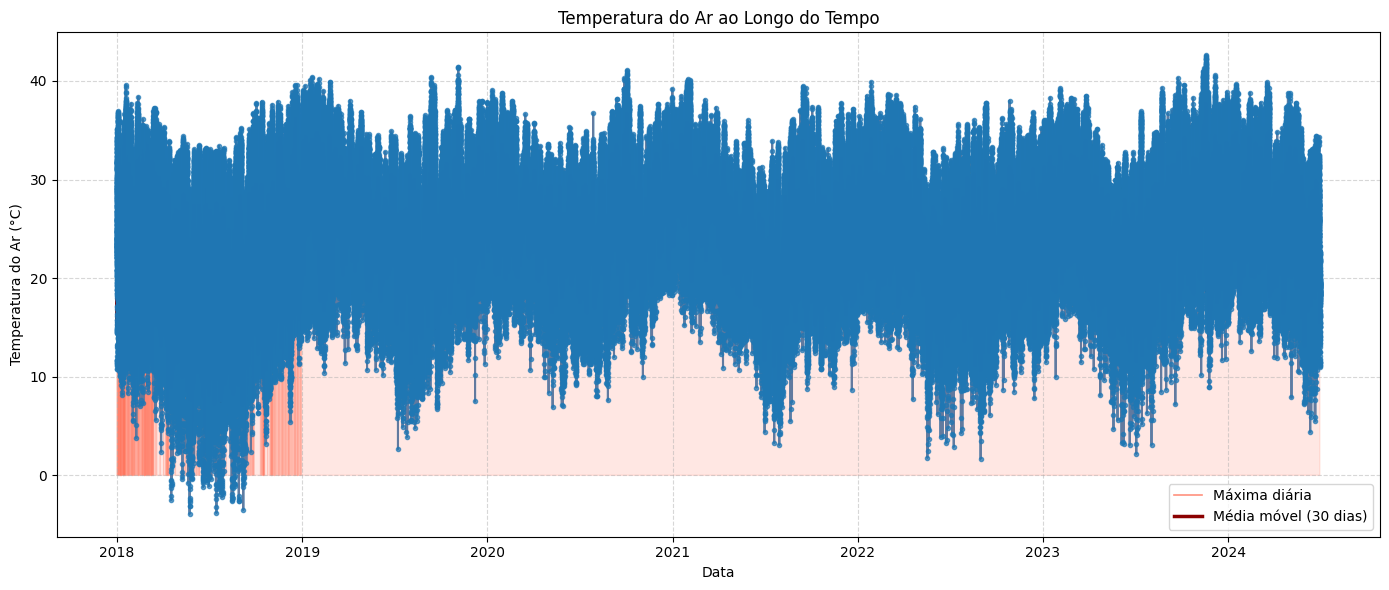

In [ ]:
import matplotlib.pyplot as plt

# Coletar dados de temperatura e data em pandas para visualização
df_plot = df_normalizado.select("data", "temperatura_maxima_na_hora_ant_aut_degc") \
    .orderBy("data") \
    .toPandas()

plt.figure(figsize=(14, 6))
plt.plot(
    df_plot["data"],
    df_plot["temperatura_maxima_na_hora_ant_aut_degc"],
    color="tomato",
    linewidth=1.2,
    alpha=0.7,
    label="Máxima diária"
)

rolling = df_plot["temperatura_maxima_na_hora_ant_aut_degc"].rolling(window=30, min_periods=1).mean()
plt.plot(
    df_plot["data"],
    rolling,
    color="darkred",
    linewidth=2.5,
    label="Média móvel (30 dias)"
)

plt.fill_between(
    df_plot["data"],
    df_plot["temperatura_maxima_na_hora_ant_aut_degc"],
    color="tomato",
    alpha=0.15
)

plt.xlabel("Data")
plt.ylabel("Temperatura máxima (°C)")
plt.title("Temperatura Máxima ao Longo do Tempo")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.plot(df_plot["data"], df_plot["temperatura_maxima_na_hora_ant_aut_degc"], marker='.', linestyle='-', alpha=0.7)
plt.xlabel("Data")
plt.ylabel("Temperatura do Ar (°C)")
plt.title("Temperatura do Ar ao Longo do Tempo")
plt.grid(True)
plt.tight_layout()
plt.show()

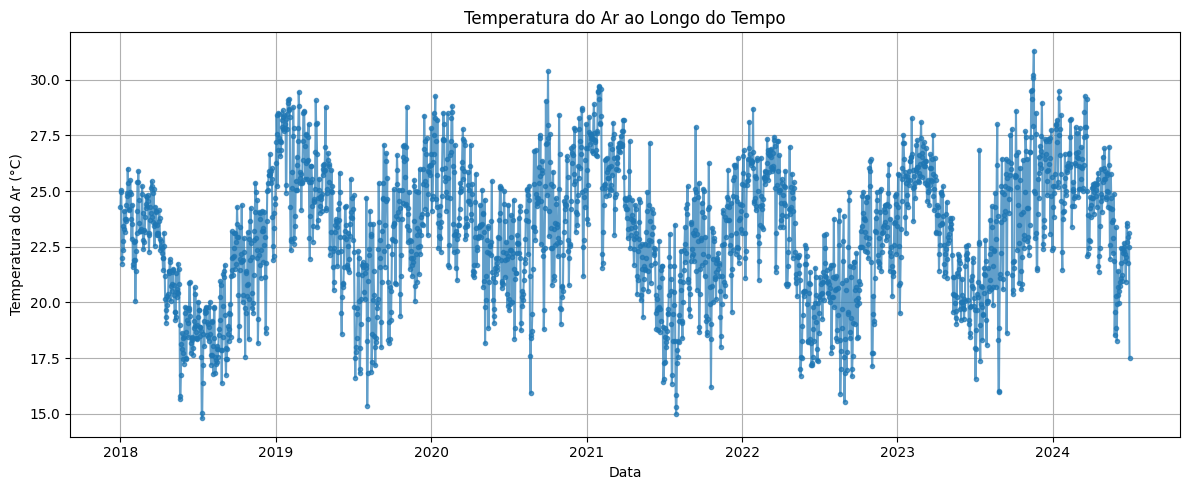

In [ ]:
import pandas as pd

# Coletar dados de temperatura e data em pandas para visualização
df_plot = df_normalizado.select("data", "temperatura_minima_na_hora_ant_aut_degc") \
    .orderBy("data") \
    .toPandas()

df_plot["data"] = pd.to_datetime(df_plot["data"], errors="coerce")
col_temp = "temperatura_minima_na_hora_ant_aut_degc"

df_plot = (
    df_plot.dropna(subset=["data", col_temp])
    .set_index("data")[col_temp]
    .resample("D")
    .mean()
    .dropna()
    .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(df_plot["data"], df_plot["temperatura_minima_na_hora_ant_aut_degc"], marker='.', linestyle='-', alpha=0.7)
plt.xlabel("Data")
plt.ylabel("Temperatura do Ar (°C)")
plt.title("Temperatura do Ar ao Longo do Tempo")
plt.grid(True)
plt.tight_layout()
plt.show()

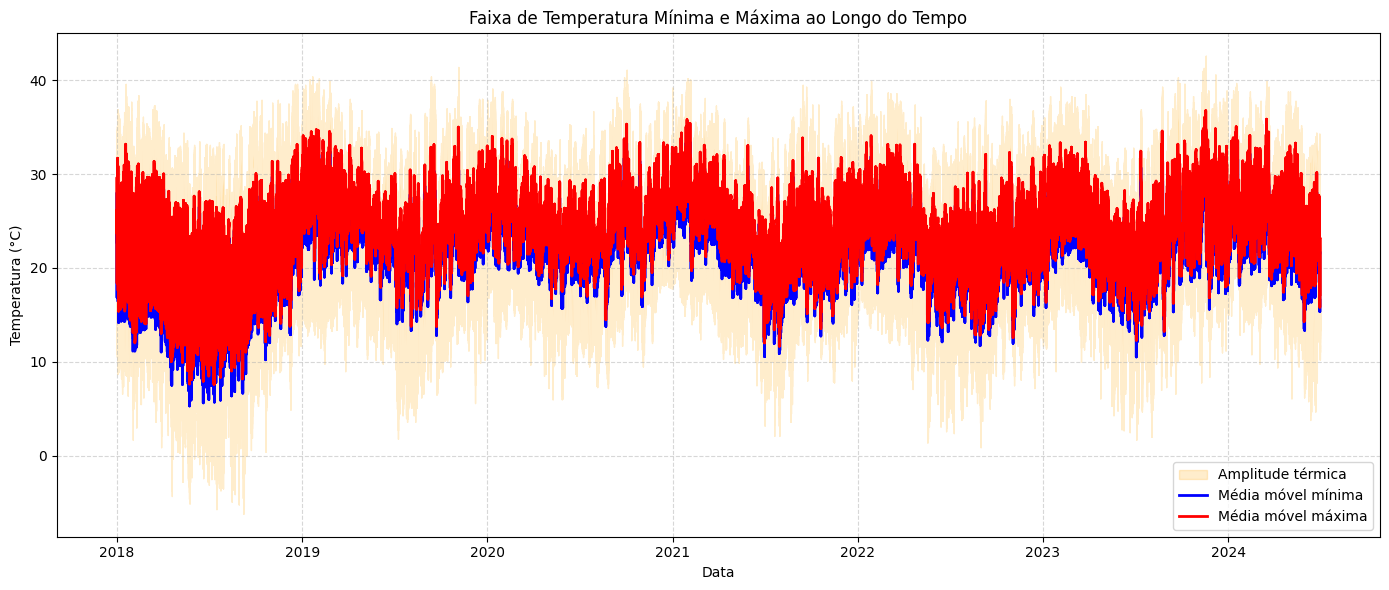

In [ ]:
# Coletar dados das temperaturas mínima e máxima para visualização
df_plot_min_max = df_normalizado.select(
    "data",
    "temperatura_minima_na_hora_ant_aut_degc",
    "temperatura_maxima_na_hora_ant_aut_degc"
).orderBy("data").toPandas()

df_plot_min_max["data"] = pd.to_datetime(df_plot_min_max["data"], errors="coerce")

df_plot_min_max = (
    df_plot_min_max
    .dropna(subset=[
        "data",
        "temperatura_minima_na_hora_ant_aut_degc",
        "temperatura_maxima_na_hora_ant_aut_degc"
    ])
    .sort_values("data")
)

temp_min = df_plot_min_max["temperatura_minima_na_hora_ant_aut_degc"]
temp_max = df_plot_min_max["temperatura_maxima_na_hora_ant_aut_degc"]

plt.figure(figsize=(14, 6))

plt.fill_between(
    df_plot_min_max["data"],
    temp_min,
    temp_max,
    color="orange",
    alpha=0.2,
    label="Amplitude térmica"
)

plt.plot(
    df_plot_min_max["data"],
    temp_min.rolling(30, min_periods=1).mean(),
    color="blue",
    linewidth=2,
    label="Média móvel mínima"
)

plt.plot(
    df_plot_min_max["data"],
    temp_max.rolling(30, min_periods=1).mean(),
    color="red",
    linewidth=2,
    label="Média móvel máxima"
)

plt.xlabel("Data")
plt.ylabel("Temperatura (°C)")
plt.title("Faixa de Temperatura Mínima e Máxima ao Longo do Tempo")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

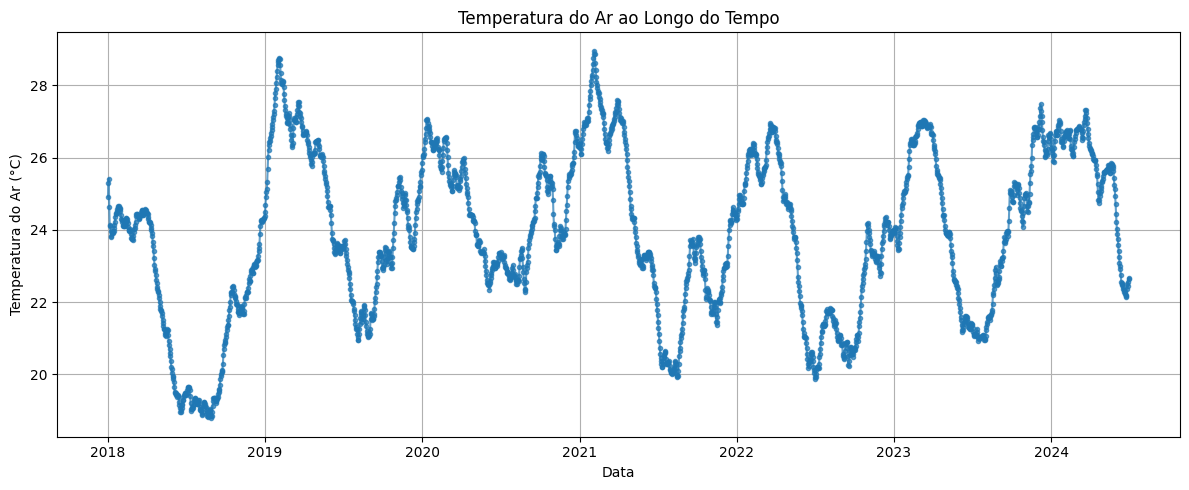

In [ ]:

df_plot = (
    df_normalizado
    .select("data", "temperatura_do_ar_bulbo_seco_horaria_degc")
    .orderBy("data")
    .toPandas()
)

df_plot["data"] = pd.to_datetime(df_plot["data"], errors="coerce")

coluna_temp = "temperatura_do_ar_bulbo_seco_horaria_degc"

df_plot = (
    df_plot
    .dropna(subset=["data", coluna_temp])
    .set_index("data")[coluna_temp]
    .resample("D")
    .mean()
    .rolling(window=30, min_periods=1)
    .mean()
    .reset_index(name=coluna_temp)
)

plt.figure(figsize=(12, 5))
plt.plot(df_plot["data"], df_plot["temperatura_do_ar_bulbo_seco_horaria_degc"], marker='.', linestyle='-', alpha=0.7)
plt.xlabel("Data")
plt.ylabel("Temperatura do Ar (°C)")
plt.title("Temperatura do Ar ao Longo do Tempo")
plt.grid(True)
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

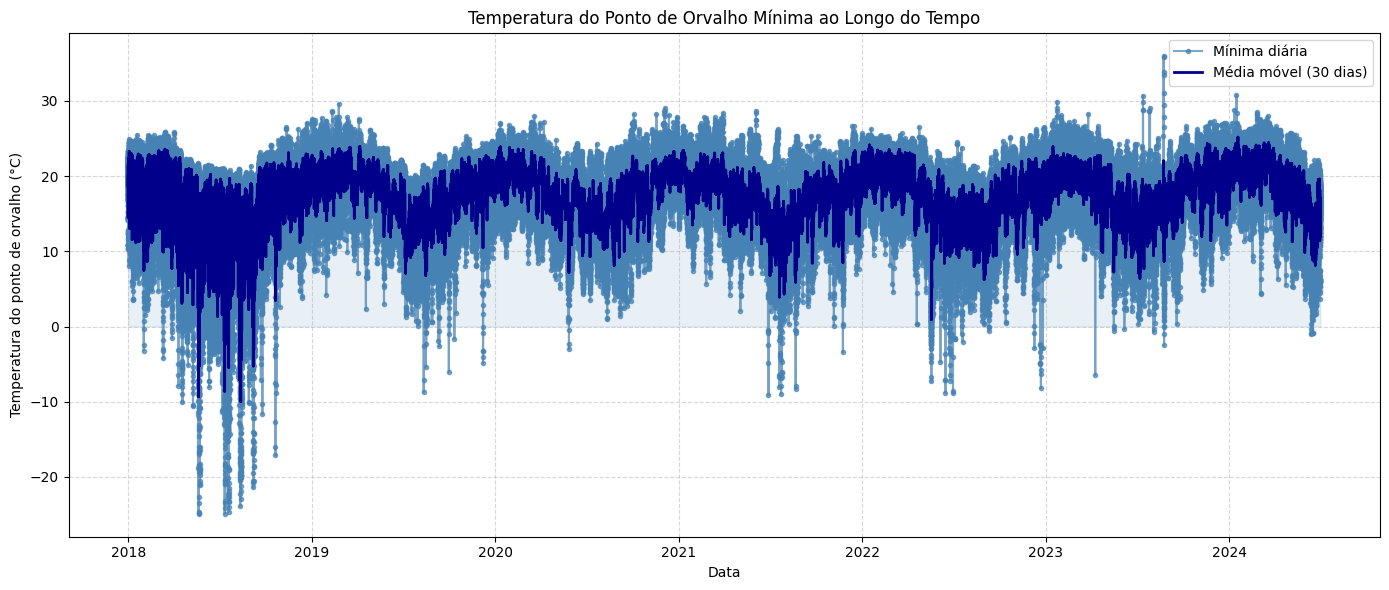

In [ ]:
df_plot = df_normalizado.select("data", "temperatura_orvalho_min_na_hora_ant_aut_degc") \
    .orderBy("data") \
    .toPandas()

plt.figure(figsize=(12, 5))
df_plot["data"] = pd.to_datetime(df_plot["data"], errors="coerce")
coluna = "temperatura_orvalho_min_na_hora_ant_aut_degc"

df_plot = (
    df_plot.dropna(subset=["data", coluna])
    .sort_values("data")
    .reset_index(drop=True)
)

rolling = df_plot[coluna].rolling(window=30, min_periods=1).mean()

plt.figure(figsize=(14, 6))
plt.plot(
    df_plot["data"],
    df_plot[coluna],
    marker=".",
    linestyle="-",
    alpha=0.7,
    color="steelblue",
    label="Mínima diária"
)
plt.plot(
    df_plot["data"],
    rolling,
    color="darkblue",
    linewidth=2,
    label="Média móvel (30 dias)"
)
plt.fill_between(
    df_plot["data"],
    df_plot[coluna],
    color="steelblue",
    alpha=0.12
)
plt.xlabel("Data")
plt.ylabel("Temperatura do ponto de orvalho (°C)")
plt.title("Temperatura do Ponto de Orvalho Mínima ao Longo do Tempo")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

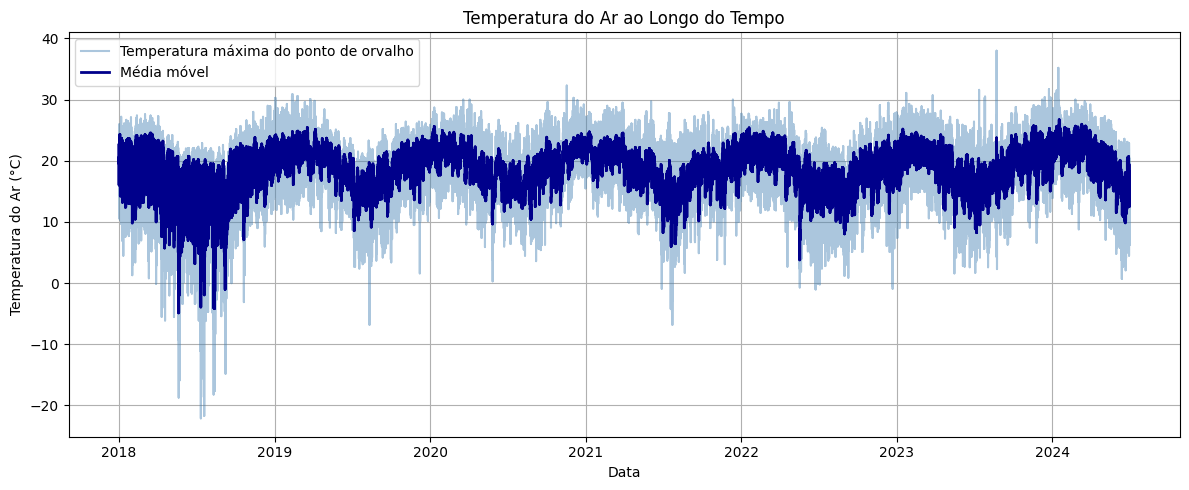

In [ ]:
# Coletar dados de temperatura e data em pandas para visualização
df_plot = df_normalizado.select("data", "temperatura_orvalho_max_na_hora_ant_aut_degc") \
    .orderBy("data") \
    .toPandas()

plt.figure(figsize=(12, 5))
plt.plot(df_plot["data"], df_plot["temperatura_orvalho_max_na_hora_ant_aut_degc"], marker='.', linestyle='-', alpha=0.7)
df_plot["data"] = pd.to_datetime(df_plot["data"], errors="coerce")
coluna = "temperatura_orvalho_max_na_hora_ant_aut_degc"

df_plot = df_plot.dropna(subset=["data", coluna]).sort_values("data")

# Redesenhar após tratar os dados
plt.cla()

plt.plot(
    df_plot["data"],
    df_plot[coluna],
    color="steelblue",
    alpha=0.45,
    label="Temperatura máxima do ponto de orvalho"
)

plt.plot(
    df_plot["data"],
    df_plot[coluna].rolling(window=30, min_periods=1).mean(),
    color="darkblue",
    linewidth=2,
    label="Média móvel"
)

plt.xlabel("Data")
plt.ylabel("Temperatura do ponto de orvalho (°C)")
plt.legend()
plt.ylabel("Temperatura do Ar (°C)")
plt.title("Temperatura do Ar ao Longo do Tempo")
plt.grid(True)
plt.tight_layout()
plt.show()

## Análise por estação do ano

A classificação usada considera verão em dezembro, janeiro e fevereiro; outono em março, abril e maio; inverno em junho, julho e agosto; e primavera em setembro, outubro e novembro. Essa convenção é compatível com as estações astronômicas simplificadas para o hemisfério sul.

Ainda assim, a agregação por ano separa o verão em dois anos: dezembro fica em um ano e janeiro e fevereiro no seguinte. Para análises sazonais, pode ser útil criar um **ano sazonal**, atribuindo dezembro ao verão que inclui janeiro e fevereiro do ano seguinte.

A limpeza sazonal usa média e desvio padrão por estação do ano, o que pode ser mais adequado que um limite global, mas ainda pode misturar localidades e regimes climáticos distintos. Também é importante verificar se a variável indicada por `coluna` foi definida antes da execução: ela é usada nas células de tratamento e visualização, mas não aparece definida no conteúdo apresentado. Sem essa definição, essas células gerarão erro.



In [ ]:
from pyspark.sql.functions import month, when
from pyspark.sql.functions import udf
from pyspark.sql.types import StringType
from pyspark.sql import Window
from pyspark.sql.functions import avg, stddev

# Função para mapear mês para estação do ano no Brasil
def estacao_do_ano(mes):
    if mes in [12, 1, 2]:
        return "Verão"
    elif mes in [3, 4, 5]:
        return "Outono"
    elif mes in [6, 7, 8]:
        return "Inverno"
    else:
        return "Primavera"



In [ ]:
# Registrar função UDF

estacao_do_ano_udf = udf(estacao_do_ano, StringType())

from pyspark.sql.functions import col as pyspark_col

# Adicionar coluna de estação do ano
df_estacao_ano = df_normalizado.withColumn("mes", month(pyspark_col("data"))) \
                       .withColumn("estacao_ano", estacao_do_ano_udf(pyspark_col("mes")))

# Para cada estação, calcular média e desvio padrão da coluna de interesse

window_estacao_ano = Window.partitionBy("estacao_ano")


In [ ]:
df_stats_estacao_ano = df_estacao_ano.withColumn("media", avg(coluna).over(window_estacao_ano)) \
                             .withColumn("desvio", stddev(coluna).over(window_estacao_ano))

# Definir limites e substituir valores extremos por None
df_tratado_estacao_ano = df_stats_estacao_ano.withColumn(
    coluna,
    when(
        (col(coluna).isNull()) |
        (col(coluna) < (col("media") - limite * col("desvio"))) |
        (col(coluna) > (col("media") + limite * col("desvio"))),
        None
    ).otherwise(col(coluna))
).drop("mes", "media", "desvio")



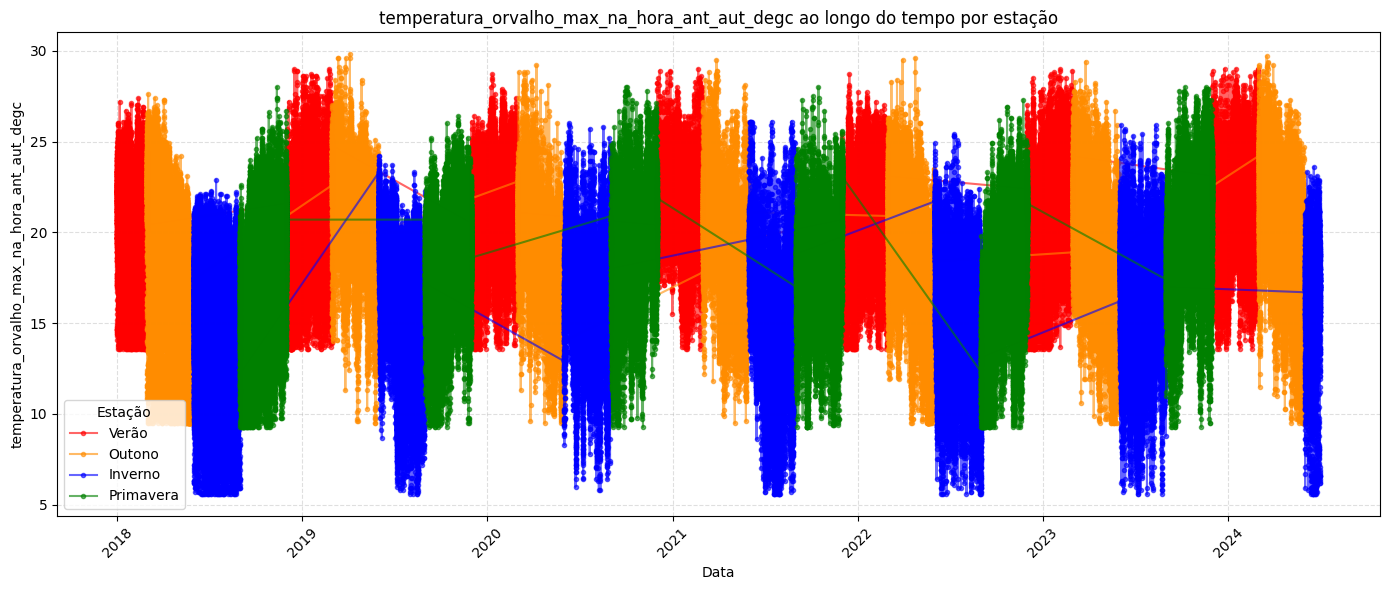

/home/spark-58eae941-a845-4eaa-96bf-9c/.ipykernel/78/command-5542698605884789-3176841475:64: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = plt.boxplot(


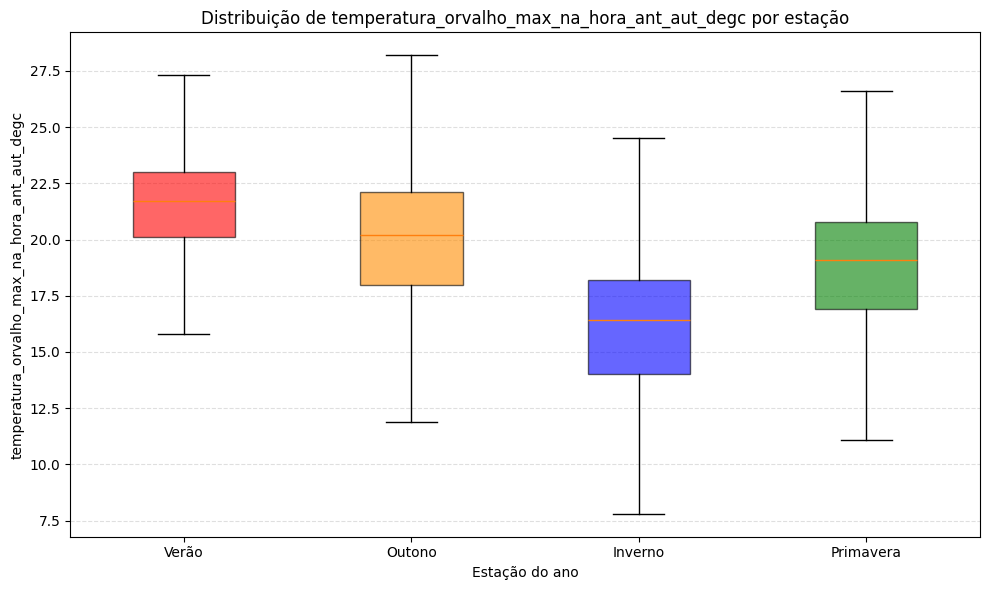

In [ ]:
df_plot_estacao_ano = (
    df_tratado_estacao_ano
    .select("data", "estacao_ano", coluna)
    .orderBy("data")
    .toPandas()
)

df_plot_estacao_ano["data"] = pd.to_datetime(
    df_plot_estacao_ano["data"],
    errors="coerce"
)

df_plot_estacao_ano = df_plot_estacao_ano.dropna(
    subset=["data", "estacao_ano", coluna]
)

cores = {
    "Verão": "red",
    "Outono": "darkorange",
    "Inverno": "blue",
    "Primavera": "green"
}

ordem_estacoes = ["Verão", "Outono", "Inverno", "Primavera"]

# Série temporal por estação
plt.figure(figsize=(14, 6))

for estacao in ordem_estacoes:
    dados = df_plot_estacao_ano[
        df_plot_estacao_ano["estacao_ano"] == estacao
    ].sort_values("data")

    if not dados.empty:
        plt.plot(
            dados["data"],
            dados[coluna],
            marker=".",
            linestyle="-",
            alpha=0.6,
            label=estacao,
            color=cores[estacao]
        )

plt.xlabel("Data")
plt.ylabel(coluna)
plt.title(f"{coluna} ao longo do tempo por estação")
plt.legend(title="Estação")
plt.grid(True, linestyle="--", alpha=0.4)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Boxplot para comparar a distribuição entre as estações
dados_boxplot = [
    df_plot_estacao_ano.loc[
        df_plot_estacao_ano["estacao_ano"] == estacao,
        coluna
    ].values
    for estacao in ordem_estacoes
]

plt.figure(figsize=(10, 6))
boxplot = plt.boxplot(
    dados_boxplot,
    labels=ordem_estacoes,
    patch_artist=True,
    showfliers=False
)

for caixa, estacao in zip(boxplot["boxes"], ordem_estacoes):
    caixa.set_facecolor(cores[estacao])
    caixa.set_alpha(0.6)

plt.xlabel("Estação do ano")
plt.ylabel(coluna)
plt.title(f"Distribuição de {coluna} por estação")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Análise de precipitação

O agrupamento da precipitação por estação do ano, ano e mês permite observar diferenças mensais e sazonais. A soma mensal, porém, só é comparável entre períodos se a cobertura dos dados for semelhante. Meses com observações ausentes ou estações inativas podem apresentar totais menores sem que tenha chovido menos.

Para tornar a análise mais robusta, convém verificar a quantidade de observações válidas por mês e por estação, além de considerar métricas como média diária, proporção de dias com dados e total mensal calculado apenas para períodos com cobertura suficiente.

A soma total por estação meteorológica também pode refletir diferenças no período de operação ou na quantidade de registros, e não apenas diferenças climáticas entre localidades. A comparação deve considerar a cobertura temporal de cada estação.



INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should

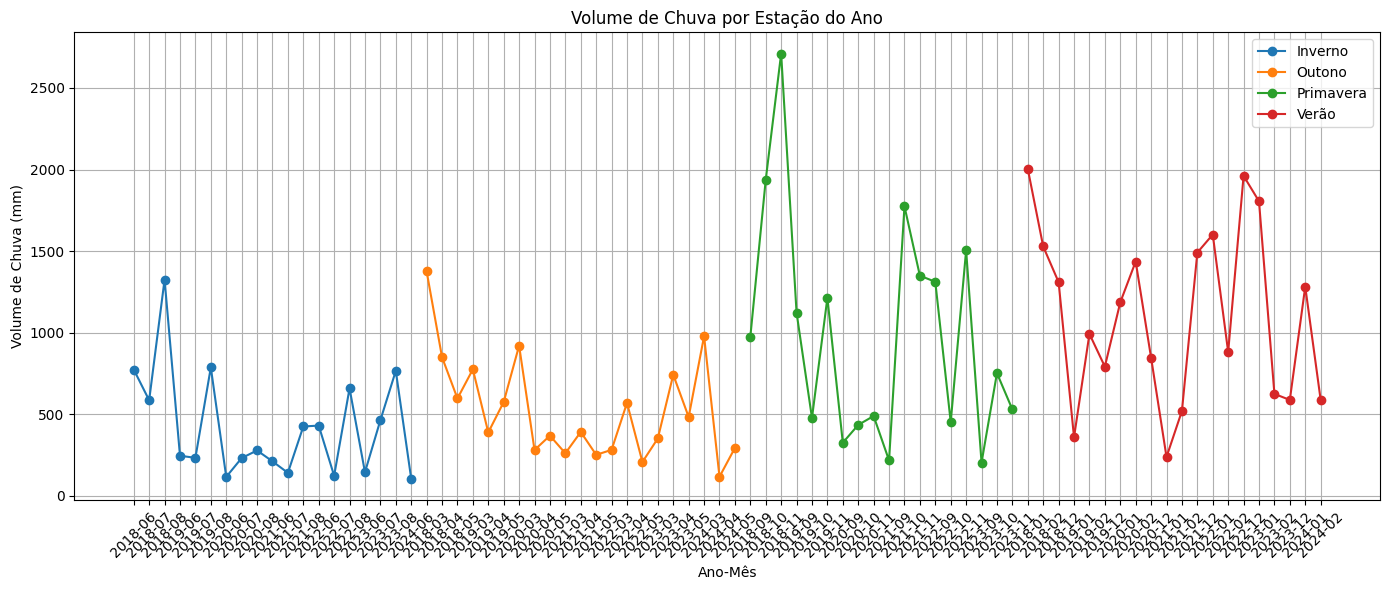

In [ ]:
# Visualizar volume de chuva por estação, mês e ano
import matplotlib.pyplot as plt

df_chuva_plot = df_chuva_estacao_ano.toPandas()

plt.figure(figsize=(14, 6))
for estacao in df_chuva_plot["estacao_ano"].unique():
    dados = df_chuva_plot[df_chuva_plot["estacao_ano"] == estacao]
    plt.plot(
        dados["ano"].astype(str) + "-" + dados["mes"].astype(str).str.zfill(2),
        dados["volume_chuva_mm"],
        marker='o',
        linestyle='-',
        label=estacao
    )

plt.xlabel("Ano-Mês")
plt.ylabel("Volume de Chuva (mm)")
plt.title("Volume de Chuva por Estação do Ano")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(True)
plt.show()

+------------------------------------+---------------------+
|estacao                             |volume_total_chuva_mm|
+------------------------------------+---------------------+
|TERESOPOLIS-PARQUE NACIONAL         |4926.000000000027    |
|ANGRA DOS REIS                      |3562.8000000000065   |
|RIO DE JANEIRO - JACAREPAGUA        |3562.6000000000067   |
|DUQUE DE CAXIAS - XEREM             |3024.000000000013    |
|SILVA JARDIM                        |2458.399999999994    |
|MACAE                               |2408.7999999999965   |
|RESENDE                             |2285.3999999999965   |
|RIO DE JANEIRO - VILA MILITAR       |2101.800000000006    |
|PICO DO COUTO                       |2057.9999999999986   |
|PARATI                              |1956.0000000000018   |
|NOVA FRIBURGO - SALINAS             |1866.399999999997    |
|RIO DE JANEIRO - FORTE DE COPACABANA|1824.1999999999987   |
|SAQUAREMA - SAMPAIO CORREIA         |1696.5999999999956   |
|RIO CLARO              

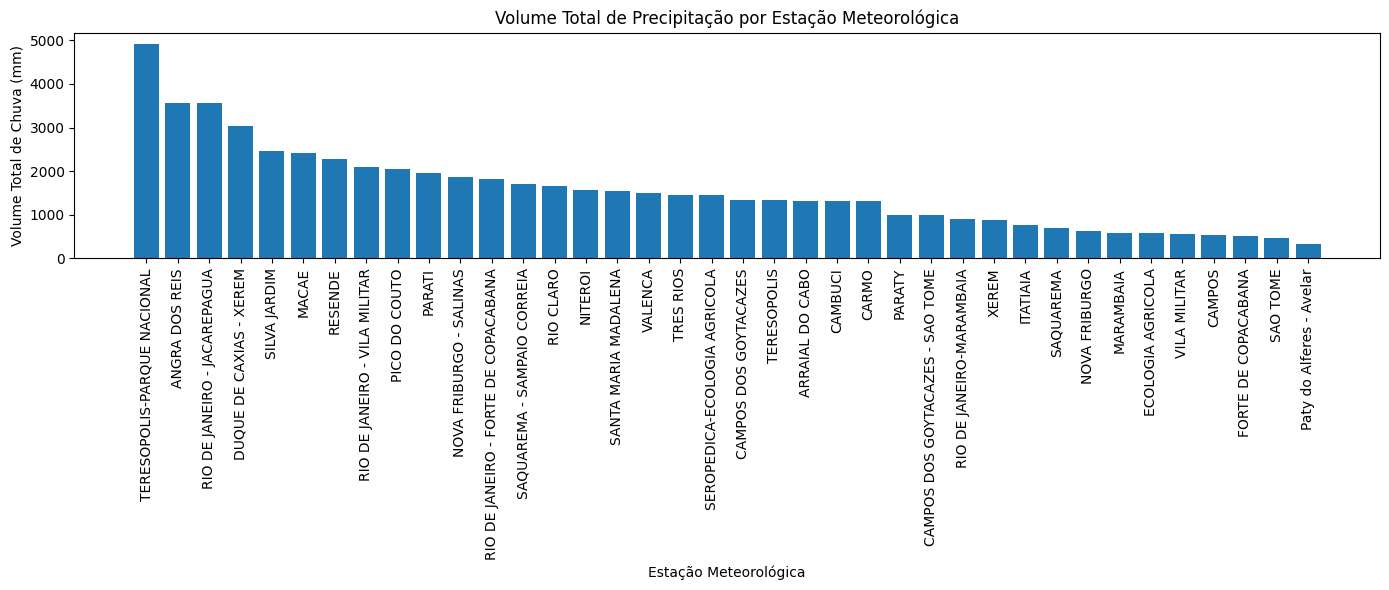

In [ ]:
# Agrupar e calcular o volume total de precipitação por estação meteorológica
df_chuva_por_estacao = df_normalizado.groupBy("estacao").sum("precipitacao_total_horario_mm") \
    .withColumnRenamed("sum(precipitacao_total_horario_mm)", "volume_total_chuva_mm") \
    .orderBy("volume_total_chuva_mm", ascending=False)

df_chuva_por_estacao.show(truncate=False)

# Visualizar o volume de chuva por estação meteorológica
df_chuva_por_estacao_pd = df_chuva_por_estacao.toPandas()

plt.figure(figsize=(14, 6))
plt.bar(df_chuva_por_estacao_pd["estacao"], df_chuva_por_estacao_pd["volume_total_chuva_mm"])
plt.xlabel("Estação Meteorológica")
plt.ylabel("Volume Total de Chuva (mm)")
plt.title("Volume Total de Precipitação por Estação Meteorológica")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Interpretação dos resultados

A análise dos dados meteorológicos permite observar diferentes comportamentos de temperatura e precipitação no estado do Rio de Janeiro entre 2018 e 2024. Como o conjunto reúne registros provenientes de diferentes estações meteorológicas, os resultados representam uma combinação de condições observadas em diferentes localidades, altitudes e características geográficas do estado.

### Temperatura

Os gráficos de temperatura mostram uma variação clara ao longo do período analisado. A temperatura do ar apresenta oscilações associadas principalmente à sazonalidade, com valores geralmente mais elevados durante o verão e menores durante o inverno. As diferenças entre as temperaturas mínima e máxima também evidenciam a variação das condições atmosféricas ao longo do tempo.

Entretanto, a interpretação dessa variação precisa considerar a distribuição geográfica das estações. O estado do Rio de Janeiro apresenta áreas costeiras, baixadas e regiões serranas com características bastante diferentes. A altitude é particularmente importante nesse contexto: estações localizadas em regiões de maior altitude, como áreas da Região Serrana, tendem a apresentar temperaturas inferiores às observadas em localidades próximas ao nível do mar.

Dessa forma, parte da variação observada nos gráficos não representa necessariamente uma mudança temporal do clima, mas também pode refletir a combinação de diferentes localidades presentes no dataset.

A temperatura do ponto de orvalho apresenta comportamento complementar à temperatura do ar. Valores elevados indicam maior presença de vapor d'água na atmosfera. Quando temperaturas elevadas ocorrem juntamente com valores elevados de ponto de orvalho e umidade, existe uma atmosfera com maior disponibilidade de umidade, condição que pode estar associada a episódios de precipitação mais intensa quando outros mecanismos atmosféricos também estão presentes.

Portanto, a análise conjunta de temperatura, umidade e ponto de orvalho fornece uma interpretação meteorológica mais adequada do que a observação isolada da temperatura.

### Comportamento sazonal

A separação dos dados por estação do ano evidencia diferenças entre verão, outono, inverno e primavera. O verão apresenta, de forma geral, temperaturas mais elevadas, enquanto o inverno apresenta os menores valores.

A precipitação também apresenta comportamento sazonal, com períodos de maior ocorrência de chuva concentrados principalmente nos meses mais quentes. Esse comportamento é compatível com a maior frequência de episódios de chuva associados à convecção durante o período de verão.

Entretanto, os gráficos também mostram que a precipitação não ocorre de maneira uniforme durante todo o período. Existem meses e anos com volumes significativamente diferentes, indicando que a distribuição temporal da chuva é bastante variável.

Essa variabilidade é importante porque o impacto de uma determinada quantidade de chuva depende não apenas do total acumulado, mas também da intensidade e do intervalo de tempo em que essa chuva ocorre.

### Precipitação

A precipitação apresenta uma distribuição muito diferente da temperatura. Enquanto a temperatura possui uma variação relativamente contínua, a precipitação apresenta muitos períodos com valores baixos ou nulos intercalados por episódios de chuva mais intensa.

Essa característica faz com que a média da precipitação seja pouco representativa dos eventos mais relevantes. Uma média baixa não significa necessariamente ausência de eventos extremos, pois poucos episódios de chuva intensa podem representar uma parcela significativa do volume precipitado.

Os gráficos de precipitação por mês e por estação do ano mostram essa concentração dos eventos de chuva. Períodos mais chuvosos alternam-se com períodos de menor precipitação, evidenciando a forte sazonalidade do regime de chuvas.

### Distribuição espacial da precipitação

A comparação entre as estações meteorológicas mostra diferenças importantes nos volumes acumulados registrados.

Entre as estações analisadas, Teresópolis – Parque Nacional apresenta um dos maiores volumes acumulados no conjunto de dados, seguida por estações localizadas em regiões como Angra dos Reis, Rio de Janeiro, Duque de Caxias e Silva Jardim.

Esses resultados são particularmente interessantes quando analisados espacialmente. Regiões do estado apresentam condições geográficas distintas que podem influenciar a ocorrência e a distribuição da precipitação.

Na Região Serrana, o relevo montanhoso e a altitude influenciam a circulação atmosférica e a distribuição da chuva. A presença de encostas também faz com que eventos de precipitação intensa tenham consequências diferentes das observadas em áreas predominantemente urbanas e planas.

Na Costa Verde e no Sul Fluminense, localidades como Angra dos Reis e Paraty combinam proximidade com o oceano e presença de áreas montanhosas. Essa configuração favorece condições de elevada disponibilidade de umidade e cria características pluviométricas diferentes de regiões mais interiores do estado.

Já na Região Metropolitana e na Baixada Fluminense, a elevada concentração urbana e a impermeabilização do solo tornam especialmente relevante a análise da chuva em relação ao escoamento superficial e à drenagem urbana. Nesses locais, episódios de precipitação intensa podem resultar em alagamentos, enxurradas e inundações mesmo quando o volume total de chuva não é excepcional em comparação com outras regiões.

Nas regiões Norte e Noroeste Fluminense, a interpretação da precipitação deve considerar também aspectos hidrológicos, principalmente em localidades próximas a rios e áreas de menor altitude. Nesses casos, acumulados de chuva durante períodos prolongados podem contribuir para a elevação dos níveis dos cursos d'água.

### Região Serrana e eventos de chuva intensa

Os resultados relacionados à Região Serrana merecem atenção especial. A presença de estações em localidades como Teresópolis e Nova Friburgo permite observar condições meteorológicas características de áreas de maior altitude.

Nessas regiões, a precipitação possui uma relação importante com o relevo. Em situações de chuva intensa ou prolongada, a água infiltrada pode aumentar a saturação do solo. Em terrenos inclinados e geologicamente suscetíveis, essa condição pode contribuir para movimentos de massa.

Assim, a interpretação dos dados indica que o volume de precipitação deve ser analisado conjuntamente com características do território. Uma determinada quantidade de chuva pode apresentar consequências diferentes dependendo da declividade, do tipo de solo, da ocupação das encostas e da quantidade de chuva acumulada anteriormente.

### Relação entre temperatura e precipitação

A comparação entre temperatura e precipitação não indica que temperaturas mais elevadas, isoladamente, sejam responsáveis pela ocorrência de chuvas intensas.

O que pode ser observado é que os períodos mais quentes coincidem, em determinadas épocas do ano, com maior ocorrência de precipitação. Essa relação está associada à dinâmica atmosférica e à disponibilidade de umidade, mas não deve ser interpretada como uma relação direta de causa e efeito apenas a partir dos gráficos.

A análise do ponto de orvalho e da umidade relativa acrescenta informações importantes. Períodos com maior disponibilidade de umidade podem apresentar condições mais favoráveis à formação de precipitação, principalmente quando combinados com mecanismos atmosféricos que promovam a ascensão do ar.

Portanto, a interpretação mais adequada é considerar temperatura, ponto de orvalho, umidade e precipitação como componentes relacionados do sistema atmosférico.

### Eventos extremos de precipitação

Os dados apresentam registros de precipitação muito superiores à média, evidenciando a presença de eventos de grande intensidade.

Esses registros são particularmente importantes para a análise porque os eventos extremos, apesar de menos frequentes, podem representar os episódios de maior impacto.

Por esse motivo, os gráficos de precipitação devem ser interpretados com atenção ao tratamento estatístico aplicado aos dados. A utilização de limites baseados na média e no desvio padrão pode remover valores que estatisticamente parecem extremos, mas que representam eventos meteorológicos reais.

No caso da precipitação, portanto, valores extremos não devem ser automaticamente considerados erros. É necessário distinguir registros inválidos de eventos meteorológicos realmente extremos.

### Diferenças entre as regiões

A análise conjunta dos gráficos permite identificar que o estado apresenta diferentes contextos meteorológicos e territoriais:

* **Região Serrana:** a combinação entre altitude, relevo acidentado e precipitação intensa torna relevante a análise de movimentos de massa e instabilidade de encostas.
* **Região Metropolitana e Baixada Fluminense:** a concentração urbana e a impermeabilização do solo tornam especialmente relevantes os riscos relacionados a alagamentos, enxurradas e drenagem urbana.
* **Costa Verde e Sul Fluminense:** a combinação entre proximidade do oceano, disponibilidade de umidade e relevo montanhoso merece atenção para episódios de chuva intensa e seus efeitos sobre encostas e áreas urbanizadas.
* **Norte e Noroeste Fluminense:** a análise da precipitação deve ser associada às características hidrológicas das regiões, considerando acumulados prolongados, rios e áreas sujeitas a inundação.

Dessa maneira, os gráficos não indicam apenas diferenças na quantidade de chuva entre as estações. Eles mostram que **a mesma variável meteorológica pode possuir diferentes implicações dependendo das características geográficas e urbanas da região onde o fenômeno ocorre**.

### Interpretação geral dos gráficos

De maneira geral, os resultados mostram três padrões principais:

1. **A temperatura apresenta forte componente sazonal**, com maiores valores nos meses mais quentes e menores valores durante o inverno, além de diferenças associadas à localização e altitude das estações.

2. **A precipitação apresenta elevada variabilidade temporal e espacial**, concentrando episódios de chuva em determinados períodos e localidades, com ocorrência de valores extremos que merecem análise específica.

3. **As condições meteorológicas não podem ser interpretadas separadamente das características territoriais.** Altitude, relevo, proximidade do oceano e urbanização modificam a forma como os eventos de precipitação podem se manifestar e produzir impactos.

Assim, os gráficos permitem compreender não apenas quando e onde ocorrem maiores valores de temperatura ou precipitação, mas também fornecem elementos para investigar por que determinadas regiões podem apresentar maior exposição a diferentes tipos de impactos associados às condições meteorológicas.



## Conclusão

A análise dos dados meteorológicos do estado do Rio de Janeiro permitiu identificar padrões temporais, sazonais e espaciais relacionados principalmente à temperatura, umidade e precipitação. Os resultados demonstram que essas variáveis não devem ser analisadas isoladamente, uma vez que as características geográficas e ambientais de cada região influenciam tanto o comportamento meteorológico quanto os possíveis impactos associados aos eventos de chuva.

A temperatura apresentou comportamento sazonal bem definido, com valores mais elevados nos períodos mais quentes e redução durante os meses de inverno. Entretanto, as diferenças observadas entre as estações também estão relacionadas à localização e à altitude, evidenciando a diversidade climática existente no território fluminense. Regiões serranas, áreas costeiras, baixadas e regiões do interior apresentam características distintas e, consequentemente, diferentes comportamentos das variáveis meteorológicas.

A precipitação apresentou maior variabilidade temporal e espacial, com períodos de baixa ocorrência intercalados por episódios de maior intensidade. Esse comportamento evidencia que valores médios de precipitação, embora úteis para uma caracterização geral, não são suficientes para representar os eventos potencialmente mais relevantes. Para estudos relacionados a chuvas fortes, torna-se necessário considerar também a intensidade, a duração e os acumulados em diferentes intervalos de tempo.

A análise regional reforça ainda que volumes semelhantes de precipitação podem produzir impactos diferentes dependendo das características do território. Na Região Serrana, por exemplo, a combinação entre chuva intensa ou persistente, relevo acidentado e saturação do solo pode aumentar a preocupação com movimentos de massa e instabilidade de encostas. Na Região Metropolitana e na Baixada Fluminense, por outro lado, a elevada urbanização e impermeabilização do solo tornam alagamentos, enxurradas e problemas de drenagem especialmente relevantes. Na Costa Verde e no Sul Fluminense, a interação entre umidade, relevo montanhoso e ocupação territorial também merece atenção, enquanto nas regiões Norte e Noroeste os efeitos hidrológicos e a possibilidade de inundações constituem aspectos importantes para análise.

Outro resultado relevante do trabalho foi a identificação da necessidade de um tratamento diferenciado para os valores extremos de precipitação. Em análises meteorológicas voltadas para eventos severos, registros muito superiores à média não devem ser automaticamente removidos como outliers, pois podem representar justamente os fenômenos de maior interesse. Dessa forma, a etapa de tratamento dos dados deve distinguir possíveis erros de medição de eventos meteorológicos extremos reais.

O trabalho também demonstra a importância da Engenharia de Dados para esse tipo de problema. A organização, padronização, integração e processamento dos registros provenientes de diferentes estações possibilitam transformar um grande volume de dados meteorológicos em informações que podem ser exploradas de maneira temporal e espacial. Nesse contexto, o uso do Databricks e do Apache Spark permite estruturar um pipeline de processamento capaz de suportar análises mais complexas e futuras ampliações do volume de dados.

Os resultados obtidos devem ser entendidos como uma análise exploratória e não como um sistema de previsão ou classificação de risco. Os dados meteorológicos permitem identificar padrões e condições relevantes, mas a determinação do risco depende da integração com outras informações, como relevo, declividade, tipo e umidade do solo, uso e ocupação do território, rede hidrográfica e registros históricos de deslizamentos, enxurradas e inundações.

Como continuidade do trabalho, a integração dessas diferentes fontes de dados permitiria avançar de uma análise predominantemente meteorológica para uma abordagem espaço-temporal voltada à identificação de condições associadas a eventos de maior impacto. Também seria possível investigar acumulados de precipitação em diferentes janelas de tempo, como 1, 6, 24 e 72 horas, além de relacioná-los a ocorrências históricas.

Assim, mais do que identificar períodos ou localidades com maior volume de chuva, o trabalho evidencia que a compreensão dos eventos meteorológicos no estado do Rio de Janeiro exige considerar **quando, onde e em quais condições ambientais a precipitação ocorre**. Essa visão integrada constitui uma base importante para estudos futuros voltados à compreensão de eventos extremos e ao desenvolvimento de ferramentas de apoio ao monitoramento e à análise de riscos geo-hidrológicos.

# Trabalhos Futuros

- **Expansão geográfica:** Ampliar a análise para outros estados brasileiros, permitindo comparações regionais e identificação de padrões climáticos em diferentes localidades.
- **Modelagem preditiva:** Desenvolver modelos de machine learning para previsão de eventos extremos de chuva, utilizando variáveis meteorológicas históricas.
- **Integração com dados externos:** Incorporar informações de impacto (ex: registros de desastres naturais, dados socioeconômicos) para análises mais abrangentes sobre os efeitos das chuvas intensas. Integração com dados de temperatura do mar e comportamentos como do **El Niño**.
- **Automatização do pipeline:** Criar um fluxo de trabalho automatizado para ingestão, limpeza, análise e visualização dos dados, facilitando atualizações periódicas em formato python, desmembrando cada função se tornando uma Taks dentro do Pipeline.
- **Publicação de dashboards interativos:** Disponibilizar visualizações dinâmicas para consulta pública, promovendo transparência e utilidade social dos resultados.